# 3강. CNN: 합성곱부터 이미지 비교와 웹 배포까지

**대상**: 파이썬과 1, 2강 내용을 아는 입문자 · **분량**: 5교시 · **환경**: Google Colab

**저자**: 이창민 · **라이선스**: 본문 CC BY 4.0, 코드 MIT (제3자 자료 제외, NOTICE 참고)

**예상 학습 시간**: 읽고 실습까지 8~10시간(추정). 코드 전체 실행은 Apple Silicon Mac에서 약 6~10분이었습니다(4.3절 Omniglot을 줄인 설정). Colab에서는 재 보지 못했습니다.

오늘이 끝나면 다음을 할 수 있습니다.

- 역전파를 PyTorch의 자동 미분 없이 직접 구현하고, `autograd`와 비교해 맞는지 검증한다.
- 맨손 학습 코드를 `nn.Module`, `optim`, `DataLoader`로 한 단계씩 리팩터링한다.
- 합성곱, 스트라이드, 패딩, 딜레이션, 풀링, 활성화 함수를 설명하고 출력 크기를 계산한다.
- CNN으로 MNIST를 분류하고, 특징 지도(activation map)를 직접 그려 본다.
- Siamese Network로 두 이미지가 같은 대상인지 비교하고, Contrastive loss와 Triplet loss의 차이를 설명한다.
- Teachable Machine으로 만든 모델을 Netlify로 배포한다.

| 교시 | 주제 | 다루는 내용 | 구분 |
|---|---|---|---|
| 1교시 | 복습: Vanilla BP | Linear regression, 손으로 만드는 신경망, 역전파 직접 구현 | 필수 |
| 2교시 | `torch.nn` 처음부터 | `functional` → `Module` → `Linear` → `optim` → `Dataset` → `DataLoader` → validation → `fit` | 필수 |
| 3교시 | Layers와 CNN | 합성곱, 패딩, 풀링, 활성화 함수, CNN, `Sequential`, GPU, AlexNet, 현재의 CNN | 필수 |
| 4교시 | Siamese Network | Contrastive loss, Triplet loss, 얼굴 비교(AT&T), 문자 비교(Omniglot) | 4.1~4.2 필수, 4.3 선택(학습이 오래 걸림) |
| 5교시 | 웹앱 만들기 | Teachable Machine으로 학습, Netlify로 배포 | 선택(카메라 필요) |

> **사용법**: 위에서 아래로 순서대로 실행하세요. 메뉴의 `런타임 → 런타임 유형 변경`에서 **T4 GPU**를 고르면 학습이 빨라집니다. `실습` 셀은 직접 채우고, 막히면 아래의 `정답`을 펼쳐 보세요. `답`이 붙은 질문은 먼저 생각해 본 뒤 펼치세요.
>
> **막혔을 때**: 에러 메시지의 마지막 줄로 검색하고, [PyTorch 포럼](https://discuss.pytorch.org)을 찾아보세요.
>
> **원래 설정이 오래 걸리는 곳은 4.3절의 Omniglot 학습뿐입니다.** 그 셀에 안내가 있습니다. 나머지 셀은 그대로 실행해도 됩니다.

In [1]:
# 이번 강의 전체에서 쓰는 라이브러리
%pip install -q torchinfo scikit-image

import gzip
import io
import math
import pickle
import random
import urllib.request
import zipfile
from collections.abc import Callable
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms.v2 as transforms
from PIL import Image
from skimage import data as skimage_data
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchinfo import summary

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "/ device:", device)


def set_seed(seed: int = 1729) -> None:
    """파이썬, NumPy, PyTorch의 난수를 한 번에 고정합니다. 1강에서 만든 함수입니다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()

Note: you may need to restart the kernel to use updated packages.
PyTorch: 2.11.0+cu128 / device: cuda


---
# 1교시. 복습: Linear regression에서 Vanilla BP까지

앞의 두 강의에서 배운 것을 한 번에 훑습니다. 이번에는 **PyTorch가 대신해 주던 일을 직접 해 봅니다.** 그래야 2교시에서 도구를 하나씩 도입할 때 각 도구가 무엇을 덜어 주는지 보입니다.

## 1.1 Linear regression

예를 들어 몸무게로 키를 맞히는 문제를 생각해 봅시다.

- $x$: 독립 변수(independent variable), 예: 몸무게(Weight)
- $y$: 종속 변수(dependent variable), 예: 키(Height)
- 모델: $y = \alpha x + \beta$

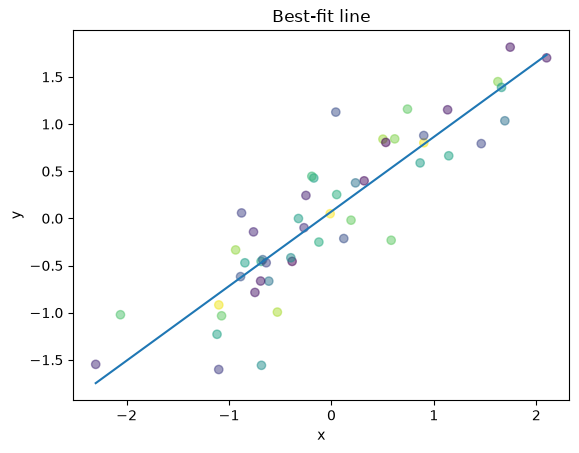

In [2]:
# x와 y가 대략 직선 관계인 점 50개를 만든다
np.random.seed(1)
n = 50
x = np.random.randn(n)
y = 0.8 * x + 0.5 * np.random.randn(n)

# 점마다 색을 다르게 칠한다
colors = np.random.rand(n)

# np.polyfit으로 최적의 직선을 구해 그린다
plt.plot(np.unique(x), np.poly1d(np.polyfit(x, y, 1))(np.unique(x)))

# 점이 겹쳐도 보이도록 alpha로 반투명하게 그린다
plt.scatter(x, y, c=colors, alpha=0.5)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Best-fit line")
plt.show()

**목표는 "점의 분포를 가장 잘 설명하는 선을 찾는 것"** 입니다. $y = \alpha x + \beta$에서 다음 두 값을 조정합니다.

- 기울기(Coefficient): $\alpha$
- 절편(Bias/intercept): $\beta$

위 그림은 `np.polyfit`이 공식으로 단번에 구한 선입니다. 지금부터는 같은 일을 경사 하강법으로 해 봅니다. 답을 아는 문제가 좋으니 정답을 정해 둡시다.

- 기울기: $\alpha = 2$
- 절편: $\beta = 1$
- 식: $y = 2x + 1$

**0부터 10까지의 값으로 리스트를 만듭니다.**

In [ ]:
x_values = [i for i in range(11)]  # range(11)은 11을 포함하지 않아 0~10이다
x_values

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

**리스트를 NumPy 배열로 바꿉니다.**

In [ ]:
x_train = np.array(x_values, dtype=np.float32)
x_train.shape

(11,)

**2차원 배열로 바꿉니다.**

데이터의 차원이 1차인 것(`[11]`)과, 2차인데 한 차원의 길이가 1인 것(`[11, 1]`)은 다릅니다. 값은 같아도 모양이 다르면 연산 결과가 달라집니다. `nn.Linear`는 `[배치, 특징 수]` 모양을 기대하므로, 특징이 하나뿐이어도 2차원으로 만들어야 합니다.

1강에서 본 `unsqueeze`가 같은 일을 합니다.

```python
x = torch.rand(3, 20, 128)
x = x.unsqueeze(dim=1)    # [3, 20, 128] -> [3, 1, 20, 128]
```

In [ ]:
# 중요: nn.Linear에 넣으려면 2차원이어야 한다
x_train = x_train.reshape(-1, 1)
x_train.shape

(11, 1)

**y 값 리스트를 만들어 NumPy 배열로 바꿉니다.** $y = 2x + 1$입니다.

In [ ]:
y_values = [2 * i + 1 for i in x_values]

# 위 한 줄은 아래 반복문과 같습니다
# y_values = []
# for i in x_values:
#     result = 2 * i + 1
#     y_values.append(result)
y_values

[1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21]

In [ ]:
y_train = np.array(y_values, dtype=np.float32)
y_train.shape

(11,)

In [ ]:
# 중요: x와 마찬가지로 2차원으로 만든다
y_train = y_train.reshape(-1, 1)
y_train.shape

(11, 1)

**모델을 만듭니다.**

1. 선형 모델을 정의합니다. 찾아야 할 정답은 $y = 2x + 1$입니다.
2. 순전파(forward)를 정의합니다. 입력이 $x = 1$이면 출력 $y$는 얼마일까요? 학습이 끝나면 3에 가까워야 합니다.

In [ ]:
class LinearRegressionModel(nn.Module):
    def __init__(self, input_dim: int, output_dim: int) -> None:
        super().__init__()
        self.linear = nn.Linear(input_dim, output_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.linear(x)
        return out

**모델 인스턴스를 만듭니다.**

- 입력: `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]`
- 원하는 출력: `[1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21]`

In [ ]:
input_dim = 1
output_dim = 1

model = LinearRegressionModel(input_dim, output_dim)

**손실 함수 인스턴스를 만듭니다.**

MSE(Mean Squared Error, 평균 제곱 오차)를 씁니다.

$$MSE = \frac{1}{n} \sum_{i=1}^n(\hat y_i - y_i)^2$$

- $\hat y$: 예측값
- $y$: 실제값

In [ ]:
criterion = nn.MSELoss()

**옵티마이저 인스턴스를 만듭니다.**

가중치를 고치는 식을 단순하게 쓰면 다음과 같습니다.

- `W_new = W_old - learning_rate * gradient`
    - `W_new`: 업데이트된 가중치
    - `learning_rate`: 학습률, 얼마나 빠르게 배울지
    - `gradient`: 파라미터의 기울기

더 단순하게 쓰면 `parameters = parameters - learning_rate * parameters_gradients`입니다.

- `parameters`: $y = wx + b$의 $w$(weight)와 $b$(bias)
- 찾고 싶은 값: $y = 2x + 1$이므로 $w = 2$, $b = 1$

In [ ]:
learning_rate = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

**모델을 학습합니다.**

In [13]:
epochs = 100
for epoch in range(epochs):
    # NumPy 배열을 텐서로 바꾼다. 메모리를 공유하므로 복사 비용이 들지 않는다
    inputs = torch.from_numpy(x_train)
    labels = torch.from_numpy(y_train)

    # 이전 기울기가 누적되지 않도록 지운다
    optimizer.zero_grad()

    # 순전파
    outputs = model(inputs)

    # 손실 계산
    loss = criterion(outputs, labels)

    # 파라미터의 기울기 계산
    loss.backward()

    # 파라미터 수정
    optimizer.step()

    # 100줄을 모두 찍으면 읽기 어려우므로 10번에 한 번만 찍는다
    if epoch % 10 == 0 or epoch == epochs - 1:
        print(f"epoch {epoch}, loss {loss.item():.4f}")

epoch 0, loss 228.4212
epoch 10, loss 0.1985
epoch 20, loss 0.1774
epoch 30, loss 0.1586
epoch 40, loss 0.1417
epoch 50, loss 0.1267
epoch 60, loss 0.1132
epoch 70, loss 0.1012
epoch 80, loss 0.0904
epoch 90, loss 0.0808
epoch 99, loss 0.0731


**예측값을 살펴봅니다.**

In [ ]:
# 추론에는 기울기 추적이 필요 없다
with torch.no_grad():
    predicted = model(torch.from_numpy(x_train)).numpy()
predicted

array([[ 0.49720576],
       [ 2.5696125 ],
       [ 4.6420193 ],
       [ 6.714426  ],
       [ 8.786833  ],
       [10.85924   ],
       [12.931646  ],
       [15.004053  ],
       [17.07646   ],
       [19.148867  ],
       [21.221273  ]], dtype=float32)

**실제값을 살펴봅니다.** 예측값이 실제값과 비슷한지 비교해 보세요.

In [ ]:
# y = 2x + 1
y_train

array([[ 1.],
       [ 3.],
       [ 5.],
       [ 7.],
       [ 9.],
       [11.],
       [13.],
       [15.],
       [17.],
       [19.],
       [21.]], dtype=float32)

**예측값과 실제값을 그려 봅니다.**

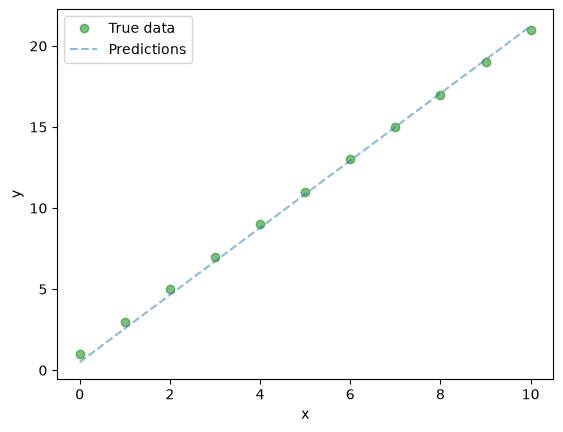

학습된 w, b: 2.072406768798828 0.4972057640552521


In [16]:
# 예측값을 구한다
with torch.no_grad():
    predicted = model(torch.from_numpy(x_train)).numpy()

# 실제 데이터
plt.plot(x_train, y_train, "go", label="True data", alpha=0.5)

# 예측
plt.plot(x_train, predicted, "--", label="Predictions", alpha=0.5)

plt.legend(loc="best")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

print("학습된 w, b:", model.linear.weight.item(), model.linear.bias.item())

정답은 $w=2, b=1$인데 학습된 값을 보면 $w$는 2에 가깝고 $b$는 1보다 꽤 작을 것입니다. 학습률이 작고 100 에폭뿐이라, 손실에 더 크게 기여하는 $w$가 먼저 맞춰지고 $b$는 천천히 따라오기 때문입니다. `epochs`를 1000으로 늘려 $b$가 1에 다가가는지 직접 확인해 보세요.

**모델을 저장합니다.**

`state_dict()`는 파라미터(여기서는 $w$와 $b$)만 담은 사전입니다. 모델 구조는 코드로 남아 있으니 파라미터만 저장하면 됩니다.

In [ ]:
save_model = True
if save_model:
    # 파라미터(w, b)만 저장한다
    torch.save(model.state_dict(), "linear_model.pt")

**모델을 불러옵니다.**

In [ ]:
load_model = True
if load_model:
    model.load_state_dict(torch.load("linear_model.pt"))

## 1.2 손으로 만드는 신경망

이번에는 `nn.Linear`도, `loss.backward()`도 쓰지 않습니다.

- `x`: \[공부한 시간, 자는 시간\]
- `y`: 성적
- 목표: `x`에서 `y`로 가는 관계를 학습합니다.
- 문제: 입력 `Xp`의 성적은 얼마로 예측할까요?

출처: [A Simple Neural Network from Scratch with PyTorch and Google Colab](https://medium.com/dair-ai/a-simple-neural-network-from-scratch-with-pytorch-and-google-colab-c7f3830618e0)

In [ ]:
X = torch.tensor(([2, 8], [1, 9], [3, 7]), dtype=torch.float)  # 3 X 2 텐서
y = torch.tensor(([86], [60], [95]), dtype=torch.float)        # 3 X 1 텐서
Xp = torch.tensor(([2.5, 8]), dtype=torch.float)               # 길이 2인 1차원 텐서

print(X, X.size())
print(y, y.size())

# 아래 실험에서 스케일링 전 값을 다시 쓰기 위해 남겨 둔다
X_raw, y_raw = X.clone(), y.clone()

# Q. 단위를 맞추는 스케일링이 효과가 있을까요? 뒤에서 실험합니다
SCALE = True
if SCALE:
    X_max, _ = torch.max(X, 0)
    X = torch.div(X, X_max)
    Xp = torch.div(Xp, X_max)
    y = y / 100  # 성적의 최댓값이 100이다

tensor([[2., 8.],
        [1., 9.],
        [3., 7.]]) torch.Size([3, 2])
tensor([[86.],
        [60.],
        [95.]]) torch.Size([3, 1])


신경망의 구조는 입력 2개, 은닉 3개, 출력 1개입니다. 손실은 $\frac{1}{2}(y-o)^2$의 합으로 두고, 체인 룰로 기울기를 직접 계산합니다.

두 가지를 짚어 둡니다.

- `sigmoidPrime(s)`는 $s(1-s)$입니다. 시그모이드의 미분은 $\sigma'(z) = \sigma(z)(1-\sigma(z))$이므로, 인자 `s`에는 $z$가 아니라 **시그모이드를 이미 통과한 값** $\sigma(z)$를 넣어야 맞습니다. 아래 코드는 `o`와 `z2`를 넣으므로 맞습니다.
- 학습 메서드의 이름을 `train`으로 지으면 안 됩니다. `nn.Module`에는 이미 `train(mode)`가 있어서 부모의 메서드를 덮어쓰고, `NN.eval()`을 부르는 순간 에러가 납니다(`eval`이 내부에서 `train(False)`를 호출합니다). 흔한 실수입니다. 그래서 `train_step`으로 짓습니다.

In [ ]:
class Neural_Network(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        # 구조를 정하는 값
        self.inputSize = 2
        self.outputSize = 1
        self.hiddenSize = 3

        # 가중치. nn.Parameter가 아니므로 parameters()에 잡히지 않는다.
        # 기울기를 직접 계산할 것이므로 일부러 일반 텐서로 둔다
        self.W1 = torch.randn(self.inputSize, self.hiddenSize)   # 2 X 3 텐서
        self.W2 = torch.randn(self.hiddenSize, self.outputSize)  # 3 X 1 텐서

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        self.z = torch.matmul(X, self.W1)         # 3 X 3
        self.z2 = self.sigmoid(self.z)            # 활성화 함수
        self.z3 = torch.matmul(self.z2, self.W2)
        o = self.sigmoid(self.z3)                 # 마지막 활성화 함수
        return o

    def sigmoid(self, s: torch.Tensor) -> torch.Tensor:
        return 1 / (1 + torch.exp(-s))

    def sigmoidPrime(self, s: torch.Tensor) -> torch.Tensor:
        # 시그모이드의 미분. s는 시그모이드를 이미 통과한 값이다
        return s * (1 - s)

    def backward(self, X: torch.Tensor, y: torch.Tensor, o: torch.Tensor) -> None:
        self.o_error = y - o  # 출력의 오차
        self.o_delta = self.o_error * self.sigmoidPrime(o)  # 오차에 시그모이드 미분을 곱한다
        self.z2_error = torch.matmul(self.o_delta, torch.t(self.W2))
        self.z2_delta = self.z2_error * self.sigmoidPrime(self.z2)
        # 오차가 y - o 이므로 기울기의 반대 방향으로 가는 것이 더하기가 된다. 학습률은 1인 셈이다
        self.W1 += torch.matmul(torch.t(X), self.z2_delta)
        self.W2 += torch.matmul(torch.t(self.z2), self.o_delta)

    def train_step(self, X: torch.Tensor, y: torch.Tensor) -> None:
        # 순전파와 역전파를 한 번씩
        o = self.forward(X)
        self.backward(X, y, o)

    def saveWeights(self, model: nn.Module) -> None:
        # 가중치가 일반 텐서라 state_dict()에 들어가지 않으므로 객체 전체를 저장한다.
        # 불러올 때는 torch.load("NN", weights_only=False)가 필요하다. 기본값 True는 객체 전체를 거부한다
        torch.save(model, "NN")

    def predict(self) -> None:
        print("학습된 가중치로 예측합니다")
        print("입력(스케일링 후):", Xp)
        print("출력:", self.forward(Xp))

In [21]:
set_seed()
NN = Neural_Network()
for i in range(1000):  # 1,000번 학습한다
    if i % 200 == 0 or i == 999:  # 1,000줄을 찍지 않도록 일부만 출력한다
        print(f"#{i} Loss: {torch.mean((y - NN(X)) ** 2).item():.6f}")  # 제곱 오차의 평균
    NN.train_step(X, y)
NN.saveWeights(NN)
NN.predict()

#0 Loss: 0.071518
#200 Loss: 0.023179
#400 Loss: 0.020117
#600 Loss: 0.014361
#800 Loss: 0.006203
#999 Loss: 0.001830
학습된 가중치로 예측합니다
입력(스케일링 후): tensor([0.8333, 0.8889])
출력: tensor([0.8677])


**스케일링이 효과가 있었을까요?** 질문으로 남겨 둔 실험을 해 봅시다. 같은 초기값에서 입력과 목표값의 스케일링을 켜고 끄며 네 가지를 비교합니다. 목표값의 단위가 다르면 손실을 비교할 수 없으므로, 오차를 **성적 점수** 로 되돌려 잽니다.

In [22]:
def manual_error_in_points(X_in: torch.Tensor, y_in: torch.Tensor, y_scale: float, steps: int = 1000) -> tuple[float, torch.Tensor]:
    """손으로 만든 신경망을 학습하고, 성적 점수 단위의 RMSE와 예측을 돌려줍니다."""
    set_seed()
    network = Neural_Network()
    for _ in range(steps):
        network.train_step(X_in, y_in)
    predictions = network(X_in) * y_scale
    return torch.sqrt(torch.mean((y_raw - predictions) ** 2)).item(), predictions.flatten()


Y_SCALE = 100.0
scaling_cases = {
    "X and y scaled": (X, y, Y_SCALE),
    "y scaled only": (X_raw, y, Y_SCALE),
    "X scaled only": (X, y_raw, 1.0),
    "no scaling": (X_raw, y_raw, 1.0),
}
for case_name, (X_case, y_case, scale) in scaling_cases.items():
    error, predictions = manual_error_in_points(X_case, y_case, scale)
    print(f"{case_name:15s} RMSE {error:6.2f}점, 예측 {predictions.tolist()}")

X and y scaled  RMSE   4.26점, 예측 [81.83625030517578, 64.9230728149414, 91.39961242675781]
y scaled only   RMSE   1.38점, 예측 [85.78631591796875, 60.382469177246094, 92.65628814697266]
X scaled only   RMSE  80.71점, 예측 [1.0, 1.0, 1.0]
no scaling      RMSE  80.71점, 예측 [1.0, 1.0, 1.0]


<details><summary>답</summary>

이 문제에서 꼭 필요한 것은 **목표값의 스케일링** 입니다. 이 신경망의 출력은 시그모이드를 지나므로 항상 0과 1 사이인데, 목표값은 60~95입니다. 어떤 가중치를 찾아도 닿을 수 없는 목표이므로, `y`를 그대로 두면 입력을 스케일링하든 말든 예측이 1에 붙어 오차가 약 80점에 머뭅니다.

입력의 스케일링은 이 실험에서 이득이 없었습니다. 위 출력에서 `y`만 스케일링한 쪽의 오차가 오히려 더 작습니다. 입력 값이 1~9로 원래 비슷한 크기라 그럴 수 있고, 시드 하나와 데이터 세 개로 한 실험입니다. 특징마다 단위가 크게 다른 데이터에서는 입력 스케일링도 중요하니, 이 결과를 일반화하지는 마세요.

</details>

## 1.3 Vanilla BackPropagation

MNIST를 MLP로 다루되, 더 기본으로 내려가 봅시다. `autograd`도 `nn.Linear`도 없이 층과 역전파를 직접 만듭니다.

참고: [DeepOrigins: Neural Network Backpropagation](https://colab.research.google.com/github/AmanDaVinci/DeepOrigins/blob/master/notebooks/03_Neural-Network-Backpropagation.ipynb)

**데이터를 불러옵니다.**

In [23]:
dataset = datasets.MNIST(root="data", download=True)

아래에서 뒤쪽 10,000장을 `x_test`라고 부르지만, 공식 테스트 세트가 아니라 **학습 세트 60,000장 중 일부** 입니다. `MNIST(train=True)`가 기본값이기 때문입니다. 이 절에서는 역전파 확인이 목적이라 이대로 씁니다. 실제 평가에서는 2강처럼 `train=False`인 공식 테스트 세트를 쓰세요.

In [24]:
x, y = dataset.data.float(), dataset.targets
x_train, x_test = x[:50000], x[50000:]
y_train, y_test = y[:50000], y[50000:]

x_train.shape, x_test.shape

(torch.Size([50000, 28, 28]), torch.Size([10000, 28, 28]))

**이미지를 펼칩니다(Flatten).** 28×28 이미지를 784차원 벡터로 바꿉니다.

In [ ]:
# 펼치기 전에 첫 이미지를 남겨 둔다. 정규화 전의 픽셀 값을 보기 위해서다
first_image_raw = x_train[0].clone()

x_train = x_train.reshape(x_train.shape[0], x_train.shape[1] * x_train.shape[2])
x_test = x_test.reshape(x_test.shape[0], x_test.shape[1] * x_test.shape[2])

In [ ]:
n, m = x_train.shape
# 클래스 수는 최댓값 - 최솟값 + 1이다. 0~9는 9가 아니라 10개다
c = (y_train.max() - y_train.min()).item() + 1
n, m, c

(50000, 784, 10)

**데이터를 정규화합니다.** 평균과 표준편차는 학습 데이터에서만 구하고, 같은 값으로 검증 데이터도 변환합니다.

In [ ]:
def normalize(x: torch.Tensor, mean: torch.Tensor, std: torch.Tensor) -> torch.Tensor:
    return (x - mean) / std

In [ ]:
train_mean = x_train.mean()
train_std = x_train.std()

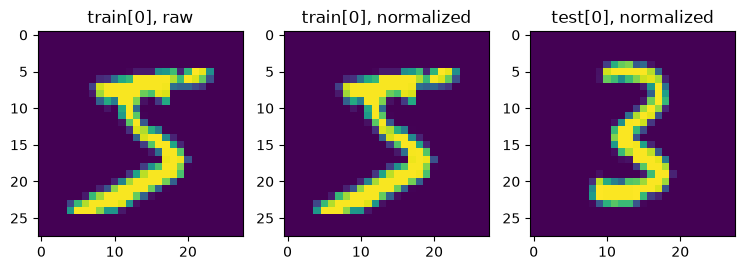

train[0] 정규화 전 범위: 0.0 255.0
train[0] 정규화 후 범위: -0.42451685667037964 2.8170278072357178
정규화 후 평균과 표준편차: 2.14245847729444e-08 1.0


In [29]:
x_train = normalize(x_train, train_mean, train_std)
x_test = normalize(x_test, train_mean, train_std)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(first_image_raw.numpy())
axes[0].set_title("train[0], raw")
axes[1].imshow(x_train[0].view(28, 28).numpy())
axes[1].set_title("train[0], normalized")
axes[2].imshow(x_test[0].view(28, 28).numpy())
axes[2].set_title("test[0], normalized")
plt.show()

# imshow가 범위를 자동으로 맞추므로 왼쪽 두 그림은 같아 보인다. 달라진 것은 값의 범위다
print("train[0] 정규화 전 범위:", first_image_raw.min().item(), first_image_raw.max().item())
print("train[0] 정규화 후 범위:", x_train[0].min().item(), x_train[0].max().item())
print("정규화 후 평균과 표준편차:", x_train.mean().item(), x_train.std().item())

**역전파를 처음부터 만듭니다.**

모든 층이 따를 규칙을 `Layer`로 정합니다. PyTorch의 `nn.Module`과 비슷한 역할입니다. 층마다 `forward`로 값을 계산하고, `backward`로 기울기를 계산합니다.

기울기는 `.g`라는 속성에 저장합니다. PyTorch의 `.grad`와 섞이지 않게 다른 이름을 씁니다. 앞 층의 출력 `y`와 뒤 층의 입력 `x`는 **같은 텐서 객체** 이므로, 뒤 층이 `self.x.g`에 값을 쓰면 앞 층이 `self.y.g`로 읽을 수 있습니다. 이것이 기울기가 뒤에서 앞으로 흐르는 통로입니다.

In [30]:
class Layer:
    """PyTorch의 nn.Module처럼 모든 층이 따르는 추상 클래스입니다."""

    def __call__(self, *args: torch.Tensor) -> torch.Tensor:
        self.args = args
        self.y = self.forward(*self.args)
        return self.y

    def __repr__(self) -> str:
        raise NotImplementedError("__repr__ method not implemented")

    def forward(self, *args: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError("forward method not implemented")

    def backward(self) -> None:
        raise NotImplementedError("backward method not implemented")

각 층의 기울기를 식으로 정리해 봅시다. 배치 크기가 $N$이고 $y = xW + b$일 때 다음과 같습니다.

- $\partial L / \partial W = x^T \cdot g_y$
- $\partial L / \partial b = \sum_{i=1}^N g_{y_i}$. 절편 하나를 $N$개 샘플이 함께 쓰므로 **샘플 방향으로 더해** 절편과 같은 크기로 만듭니다.
- $\partial L / \partial x = g_y \cdot W^T$

`bias.g = y.g`로 쓰기 쉬운데, 틀린 코드입니다. 모양이 `[N, 출력]`이라 절편 `[출력]`과 맞지 않고 값도 틀립니다. `backward`를 부르기만 해서는 에러가 나지 않아 눈치채기 어렵습니다. 그래서 아래에서 `autograd`와 비교해 검증합니다.

In [31]:
class MyLinear(Layer):
    """Kaiming 초기화를 쓰는 선형 층입니다."""

    def __init__(self, in_size: int, out_size: int) -> None:
        # ReLU와 짝을 이루는 Kaiming 초기화: 표준편차가 sqrt(2 / 입력 크기)
        self.weight = torch.randn(in_size, out_size) * ((2 / in_size) ** 0.5)
        self.bias = torch.zeros(out_size)

    def __repr__(self) -> str:
        return f"(Linear: in={self.weight.shape[0]} out={self.weight.shape[1]})"

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        self.x = x
        self.y = self.x @ self.weight + self.bias
        return self.y

    def backward(self) -> None:
        self.weight.g = self.x.t() @ self.y.g
        # 절편은 모든 샘플이 함께 쓰므로 샘플 방향으로 더한다
        self.bias.g = self.y.g.sum(0)
        self.x.g = self.y.g @ self.weight.t()

In [32]:
class MyReLU(Layer):
    """Rectified Linear Unit 층입니다."""

    def __init__(self, shift: float = 0.0) -> None:
        self.shift = shift

    def __repr__(self) -> str:
        return f"(ReLU: shift={self.shift})"

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        self.x = x
        self.y = self.x.clamp_min(0.0) - self.shift
        return self.y

    def backward(self) -> None:
        # 입력이 양수인 곳만 기울기가 통과한다(미분값 1), 나머지는 0이다
        self.x.g = self.y.g * (self.x > 0).float()

In [ ]:
class MyMSE(Layer):
    """평균 제곱 오차 층입니다. 출력이 [N, 1] 모양일 때를 가정합니다."""

    def __repr__(self) -> str:
        return "Loss: Mean Squared Error"

    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor) -> torch.Tensor:
        self.x1 = y_pred
        self.x2 = y_true
        self.y = (self.x1 - self.x2).pow(2).mean()
        return self.y

    def backward(self) -> None:
        # mean()이 나눈 개수가 샘플 수 N이므로 N으로 나눈다. 출력이 [N, D]이면 N * D로 나눠야 한다
        self.x1.g = 2 * (self.x1 - self.x2) / self.x1.shape[0]

In [ ]:
class FeedForwardNN:
    """위의 층을 쌓은 순전파 신경망입니다."""

    def __init__(self, x_dim: int, y_dim: int, n_layers: int) -> None:
        # 층의 크기를 지수적으로 줄여 나간다
        def _exp(pos: float) -> int:
            return math.ceil(x_dim * (y_dim / x_dim) ** pos)

        layer_dims = [_exp(pos / n_layers) for pos in range(0, n_layers + 1)]
        # 층 목록을 만든다
        self.layers = []
        for i in range(n_layers):
            in_dim, out_dim = layer_dims[i], layer_dims[i + 1]
            self.layers.append(MyLinear(in_dim, out_dim))
            self.layers.append(MyReLU())
        self.loss = MyMSE()

    def __repr__(self) -> str:
        model_str = "\n".join(l.__repr__() for l in self.layers)
        model_str += "\n" + self.loss.__repr__()
        return model_str

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        for l in self.layers:
            x = l.forward(x)
        return x

    def backward(self) -> None:
        self.loss.backward()
        # 기울기는 출력에서 입력 쪽으로 흐르므로 층을 거꾸로 돈다
        for layer in reversed(self.layers):
            layer.backward()

In [35]:
set_seed()
model = FeedForwardNN(x_dim=784, y_dim=1, n_layers=5)
model

(Linear: in=784 out=207)
(ReLU: shift=0.0)
(Linear: in=207 out=55)
(ReLU: shift=0.0)
(Linear: in=55 out=15)
(ReLU: shift=0.0)
(Linear: in=15 out=4)
(ReLU: shift=0.0)
(Linear: in=4 out=1)
(ReLU: shift=0.0)
Loss: Mean Squared Error

이 모델은 784차원 이미지를 숫자 하나로 줄입니다. 분류가 아니라 **레이블을 회귀** 하는 것입니다. 숫자 3과 8은 모양과 무관하게 값 차이가 크게 취급되므로 좋은 문제 정의는 아닙니다. 지금은 역전파 구조를 확인하는 것이 목적이라 단순한 쪽을 택했습니다.

`y_train`은 `[N]` 모양이므로 `unsqueeze(-1)`로 `[N, 1]`로 맞춥니다. 예측이 `[N, 1]`인데 정답이 `[N]`이면 빼기에서 브로드캐스팅이 일어나 `[N, N]`이 되고, 에러 없이 틀린 값이 나옵니다.

In [36]:
y_pred = model.forward(x_train)
loss = model.loss.forward(y_pred.float(), y_train.unsqueeze(-1).float())
model.backward()
print("loss:", loss.item())
print("첫 층 weight 기울기:", model.layers[0].weight.g.shape, "/ 절편 기울기:", model.layers[0].bias.g.shape)

loss: 26.694255828857422
첫 층 weight 기울기: torch.Size([784, 207]) / 절편 기울기: torch.Size([207])


**직접 계산한 기울기가 맞을까요?** `autograd`와 비교하면 알 수 있습니다. 1강의 방법 그대로, 가중치에 `requires_grad`를 켜고 같은 계산을 다시 합니다.

In [37]:
def linear_layers(net: FeedForwardNN) -> list[MyLinear]:
    """신경망에서 선형 층만 골라 돌려줍니다."""
    return [l for l in net.layers if isinstance(l, MyLinear)]


def check_gradients(net: FeedForwardNN, xb: torch.Tensor, yb: torch.Tensor) -> None:
    """직접 구한 기울기(.g)와 autograd가 구한 기울기(.grad)를 비교합니다."""
    # 1) 직접 구현한 역전파
    net.loss.forward(net.forward(xb), yb)
    net.backward()

    # 2) 같은 계산을 autograd로 한 번 더
    for layer in linear_layers(net):
        layer.weight.requires_grad_()
        layer.bias.requires_grad_()
    net.loss.forward(net.forward(xb), yb).backward()

    for i, layer in enumerate(linear_layers(net)):
        same_w = torch.allclose(layer.weight.g, layer.weight.grad, atol=1e-5, rtol=1e-3)
        same_b = torch.allclose(layer.bias.g, layer.bias.grad, atol=1e-5, rtol=1e-3)
        print(f"층 {i}: weight 일치 {same_w}, bias 일치 {same_b}, 기울기 크기 {layer.weight.grad.norm().item():.4f}")
        assert same_w and same_b

    # 다음 학습에 영향이 없도록 autograd 흔적을 지운다
    for layer in linear_layers(net):
        layer.weight.requires_grad_(False)
        layer.bias.requires_grad_(False)
        layer.weight.grad = None
        layer.bias.grad = None


check_gradients(model, x_train[:256], y_train[:256].unsqueeze(-1).float())

층 0: weight 일치 True, bias 일치 True, 기울기 크기 9.1822
층 1: weight 일치 True, bias 일치 True, 기울기 크기 6.7533
층 2: weight 일치 True, bias 일치 True, 기울기 크기 4.9545
층 3: weight 일치 True, bias 일치 True, 기울기 크기 2.3454
층 4: weight 일치 True, bias 일치 False, 기울기 크기 7.0408


AssertionError: 

모든 층이 일치하고 기울기 크기도 0이 아닙니다. (전부 0이면 일치해도 아무 의미가 없습니다.) 기울기가 있으니 이제 `optim` 없이 파라미터를 직접 고쳐 학습할 수 있습니다. 기울기가 맞아도 실제로 손실이 줄어드는지 봐야 끝까지 확인한 것입니다.

In [ ]:
lr_manual = 0.01
targets = y_train.unsqueeze(-1).float()
for step in range(201):
    loss = model.loss.forward(model.forward(x_train), targets)
    model.backward()
    # 파라미터를 직접 고친다. 2교시에 optim이 대신할 일이다
    for layer in linear_layers(model):
        layer.weight -= lr_manual * layer.weight.g
        layer.bias -= lr_manual * layer.bias.g
    if step % 50 == 0:
        print(f"step {step}, loss {loss.item():.4f}")
print("레이블의 분산(평균만 맞혔을 때의 MSE):", targets.var().item())

step 0, loss 26.6943


step 50, loss 3.6588


step 100, loss 2.2653


step 150, loss 1.7486


step 200, loss 1.4841
레이블의 분산(평균만 맞혔을 때의 MSE): 8.359589576721191


손실이 레이블의 분산보다 한참 아래로 내려갔다면, 모델이 "평균 하나만 답하기"보다 나은 것을 배웠다는 뜻입니다. 직접 만든 역전파와 경사 하강으로 학습이 됩니다.

**이것을 PyTorch로 만든다면?** 코드가 훨씬 짧아집니다. 다만 다음처럼 쓰면 함정에 빠집니다.

```python
self.layers = [nn.Linear(x_dim, h_dim), nn.ReLU(), nn.Linear(h_dim, y_dim)]
```

파이썬 **리스트** 에 담은 층은 PyTorch가 찾아내지 못합니다. `parameters()`가 비어 옵티마이저에 넘길 것이 없고, `.to(device)`로도 옮겨지지 않습니다. `nn.Sequential`이나 `nn.ModuleList`를 써야 합니다.

In [ ]:
class TorchModelWithList(nn.Module):
    def __init__(self, x_dim: int, h_dim: int, y_dim: int) -> None:
        super().__init__()
        self.layers = [nn.Linear(x_dim, h_dim), nn.ReLU(), nn.Linear(h_dim, y_dim)]  # 파이썬 리스트
        self.loss = nn.MSELoss()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        for l in self.layers:
            x = l(x)
        return x


class TorchModel(nn.Module):
    def __init__(self, x_dim: int, h_dim: int, y_dim: int) -> None:
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(x_dim, h_dim), nn.ReLU(), nn.Linear(h_dim, y_dim)])
        self.loss = nn.MSELoss()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        for l in self.layers:
            x = l(x)
        return x


bad_model = TorchModelWithList(784, 400, 1)
torch_model = TorchModel(784, 400, 1)
print("리스트로 담은 모델의 파라미터 수:", sum(p.numel() for p in bad_model.parameters()))
print("ModuleList로 담은 모델의 파라미터 수:", sum(p.numel() for p in torch_model.parameters()))

리스트로 담은 모델의 파라미터 수: 0
ModuleList로 담은 모델의 파라미터 수: 314401


### 실습 1. 역전파가 되는 tanh 층 만들기

`MyReLU`를 본떠 `MyTanh` 층을 완성하세요. $\tanh$의 미분은 $1 - \tanh^2(x)$입니다. 아래 셀을 채운 뒤, 정답의 검증 코드로 `autograd`와 비교해 보세요.

In [ ]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
class MyTanh(Layer):
    """tanh 층입니다."""

    def __repr__(self) -> str:
        return "(Tanh)"

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        self.x = x
        self.y = torch.tanh(self.x)
        return self.y

    def backward(self) -> None:
        # 체인 룰: 뒤에서 온 기울기에 tanh의 미분을 곱한다
        self.x.g = self.y.g * (1 - self.y ** 2)


x_check = torch.randn(5, 3, requires_grad=True)
tanh_layer = MyTanh()
out = tanh_layer.forward(x_check)
out.sum().backward()
out.g = torch.ones_like(out)  # sum의 기울기는 모두 1이다
tanh_layer.backward()
assert torch.allclose(x_check.g, x_check.grad)
print("autograd와 일치합니다")
```

</details>

---
# 2교시. `torch.nn` 처음부터 만들어 보기

1교시에는 모든 것을 손으로 했습니다. 이번 교시에는 맨손으로 만든 MNIST 학습 코드를 **한 번에 도구 하나씩** 바꿔 나갑니다. 각 단계에서 무엇이 짧아지는지 비교해 보세요.

| 단계 | 도입하는 도구 | 덜어 주는 일 |
|---|---|---|
| 2.2 | `torch.nn.functional` | 손실 함수를 직접 쓰는 일 |
| 2.3 | `nn.Module`, `nn.Parameter` | 파라미터를 하나씩 고치고 지우는 일 |
| 2.4 | `nn.Linear` | 가중치와 절편을 직접 만들고 곱하는 일 |
| 2.5 | `torch.optim` | 파라미터 갱신 코드 |
| 2.6 | `Dataset` | `x`와 `y`를 따로 자르는 일 |
| 2.7 | `DataLoader` | 배치를 잘라 내는 반복문 |
| 2.8 | 검증(validation) | 과적합을 볼 방법이 없던 문제 |
| 2.9 | `fit`, `get_data` | 학습 코드의 중복 |

참고: [PyTorch 튜토리얼 torch.nn이 실제로 무엇인가요? (한국어판)](https://colab.research.google.com/github/PyTorchKorea/tutorials-kr/blob/master/docs/_downloads/d9398fce39ca80dc4bb8b8ea55b575a8/nn_tutorial.ipynb) · [영문판](https://pytorch.org/tutorials/beginner/nn_tutorial.html)

## 2.1 맨손으로 만드는 MNIST 분류기

In [ ]:
# 이번에는 미리 학습/검증으로 나뉜 튜토리얼용 파일을 내려받는다
DATA_PATH = Path("data")
PATH = DATA_PATH / "mnist"

PATH.mkdir(parents=True, exist_ok=True)

URL = "https://github.com/pytorch/tutorials/raw/main/_static/"
FILENAME = "mnist.pkl.gz"

if not (PATH / FILENAME).exists():
    with urllib.request.urlopen(URL + FILENAME, timeout=120) as response:
        (PATH / FILENAME).write_bytes(response.read())

**데이터를 처리합니다.**

In [ ]:
with gzip.open((PATH / FILENAME).as_posix(), "rb") as f:
    ((x_train, y_train), (x_valid, y_valid), _) = pickle.load(f, encoding="latin-1")

각 이미지는 28×28 형태이고, 784(=28×28) 크기의 한 행으로 저장되어 있습니다. 하나를 살펴봅시다. 그리려면 먼저 2차원으로 재구성해야 합니다.

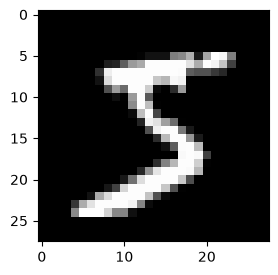

(50000, 784)


In [ ]:
plt.figure(figsize=(3, 3))
plt.imshow(x_train[0].reshape((28, 28)), cmap="gray")
plt.show()
print(x_train.shape)

**torch 텐서로 변환합니다.**

In [ ]:
x_train, y_train, x_valid, y_valid = map(torch.tensor, (x_train, y_train, x_valid, y_valid))
n, c = x_train.shape
print(x_train, y_train)
print(x_train.shape)
print(y_train.min(), y_train.max())

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]]) tensor([5, 0, 4,  ..., 8, 4, 8])
torch.Size([50000, 784])
tensor(0) tensor(9)


가중치를 직접 만듭니다. `math.sqrt(784)`로 나누는 것은 2강에서 본 Xavier 초기화와 같은 발상입니다(입력 수의 제곱근으로 나눠 분산을 맞춤). 입력 784개, 출력 10개인 선형 모델입니다.

In [ ]:
set_seed()
weights = torch.randn(784, 10) / math.sqrt(784)
weights.requires_grad_()
bias = torch.zeros(10, requires_grad=True)

`log_softmax`도 직접 씁니다. 수식은 $\log \frac{e^{x_i}}{\sum_j e^{x_j}} = x_i - \log \sum_j e^{x_j}$입니다. 모델은 로그 확률을 돌려줍니다.

In [ ]:
def log_softmax(x: torch.Tensor) -> torch.Tensor:
    return x - x.exp().sum(-1).log().unsqueeze(-1)


def model(xb: torch.Tensor) -> torch.Tensor:
    return log_softmax(xb @ weights + bias)

**배치를 나눕니다.** 학습 전의 예측을 봅시다.

In [ ]:
bs = 64  # 배치 크기

xb = x_train[0:bs]  # x에서 미니배치를 꺼낸다
preds = model(xb)   # 학습 전의 예측
print(preds[0], preds.shape)

tensor([-2.4462, -2.7077, -2.1774, -1.8391, -2.8254, -1.9926, -2.9571, -1.7652,
        -2.4864, -2.6252], grad_fn=<SelectBackward0>) torch.Size([64, 10])


**손실을 정의합니다.** 음의 로그 우도(negative log-likelihood)입니다. 모델이 이미 로그 확률을 돌려주므로, 정답 칸의 값만 골라 부호를 바꿔 평균합니다.

In [ ]:
def nll(input: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
    return -input[range(target.shape[0]), target].mean()


loss_func = nll

무작위 모델의 손실을 확인합니다. 그래야 역전파 뒤에 나아졌는지 알 수 있습니다. 10개 클래스를 고르게 찍는 모델의 손실은 $-\log(1/10) \approx 2.30$이니, 비슷한 값이 나와야 정상입니다.

In [ ]:
yb = y_train[0:bs]
print(loss_func(preds, yb))

tensor(2.4095, grad_fn=<NegBackward0>)


정확도를 계산하는 함수도 만듭시다. 예측마다 가장 큰 값의 인덱스가 정답과 같으면 맞힌 것입니다.

In [ ]:
def accuracy(out: torch.Tensor, yb: torch.Tensor) -> torch.Tensor:
    preds = torch.argmax(out, dim=1)
    return (preds == yb).float().mean()

무작위 모델의 정확도입니다. 손실이 줄면서 정확도가 오르는지 나중에 비교합니다.

In [ ]:
print(accuracy(preds, yb))

tensor(0.0469)


**학습을 시작합니다.**

In [ ]:
lr = 0.5    # 학습률
epochs = 2  # 에폭 수

for epoch in range(epochs):
    for i in range((n - 1) // bs + 1):
        start_i = i * bs
        end_i = start_i + bs
        xb = x_train[start_i:end_i]
        yb = y_train[start_i:end_i]
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        with torch.no_grad():
            weights -= weights.grad * lr
            bias -= bias.grad * lr
            weights.grad.zero_()
            bias.grad.zero_()

**결과를 확인합니다.** 앞으로 나오는 `loss_func(model(xb), yb)`의 `xb`는 반복문이 남긴 **마지막 배치** 입니다. 50,000을 64로 나눈 나머지인 16장뿐이고 학습 데이터입니다. 이 값은 "코드가 돌아가는가"를 보는 용도일 뿐 모델의 성능이 아닙니다. 성능은 2.8절의 검증 손실로 판단합니다.

In [ ]:
print(xb.shape)
print(loss_func(model(xb), yb), accuracy(model(xb), yb))

torch.Size([16, 784])
tensor(0.0814, grad_fn=<NegBackward0>) tensor(1.)


## 2.2 `torch.nn.functional`

첫 번째 리팩터링입니다. 직접 만든 `log_softmax`와 `nll`을 `F.cross_entropy` 하나로 바꿉니다. `F.cross_entropy`는 내부에서 `log_softmax`까지 처리하므로 모델은 **logit을 그대로** 돌려줘야 합니다.

In [ ]:
loss_func = F.cross_entropy


def model(xb: torch.Tensor) -> torch.Tensor:
    return xb @ weights + bias

더 이상 `model` 함수에서 `log_softmax`를 호출하지 않습니다. 손실과 정확도가 이전과 같은지 확인합시다.

In [ ]:
print(loss_func(model(xb), yb), accuracy(model(xb), yb))

tensor(0.0814, grad_fn=<NllLossBackward0>) tensor(1.)


## 2.3 `nn.Module`

가중치와 절편, 순전파를 클래스 하나에 담습니다. `nn.Parameter`로 감싸면 PyTorch가 학습할 값으로 인식합니다.

In [ ]:
class Mnist_Logistic(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.weights = nn.Parameter(torch.randn(784, 10) / math.sqrt(784))
        self.bias = nn.Parameter(torch.zeros(10))

    def forward(self, xb: torch.Tensor) -> torch.Tensor:
        return xb @ self.weights + self.bias

이제 함수가 아니라 객체이므로 **인스턴스** 를 만듭니다.

In [ ]:
model = Mnist_Logistic()

In [ ]:
print(loss_func(model(xb), yb))

tensor(2.2750, grad_fn=<NllLossBackward0>)


이전에는 파라미터를 이름으로 하나씩 고쳤습니다. 이제는 `model.parameters()`로 돌면 되고 파라미터가 몇 개든 코드가 같습니다. 기울기도 `model.zero_grad()` 한 줄로 지웁니다.

In [ ]:
def fit() -> None:
    for epoch in range(epochs):
        for i in range((n - 1) // bs + 1):
            start_i = i * bs
            end_i = start_i + bs
            xb = x_train[start_i:end_i]
            yb = y_train[start_i:end_i]
            pred = model(xb)
            loss = loss_func(pred, yb)

            loss.backward()
            with torch.no_grad():
                for p in model.parameters():
                    p -= p.grad * lr
                model.zero_grad()


fit()

In [ ]:
print(loss_func(model(xb), yb))

tensor(0.0801, grad_fn=<NllLossBackward0>)


## 2.4 `nn.Linear`

가중치와 절편을 직접 만들고 곱하는 대신 `nn.Linear`를 씁니다. 초기화까지 알아서 해 줍니다.

In [ ]:
class Mnist_Logistic(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.lin = nn.Linear(784, 10)

    def forward(self, xb: torch.Tensor) -> torch.Tensor:
        return self.lin(xb)

이전과 같은 방식으로 인스턴스를 만들고 손실을 계산합니다.

In [ ]:
model = Mnist_Logistic()
print(loss_func(model(xb), yb))

tensor(2.3413, grad_fn=<NllLossBackward0>)


`fit`은 모델 내부를 가정하지 않으므로 그대로 쓸 수 있습니다.

In [ ]:
fit()

print(loss_func(model(xb), yb))

tensor(0.0825, grad_fn=<NllLossBackward0>)


## 2.5 `torch.optim`

파라미터를 고치는 부분을 옵티마이저에 맡깁니다.

```python
# 이전
with torch.no_grad():
    for p in model.parameters():
        p -= p.grad * lr
    model.zero_grad()

# 이후
opt.step()
opt.zero_grad()
```

In [ ]:
from torch import optim

나중에 다시 쓸 수 있도록 모델과 옵티마이저를 만드는 작은 함수를 정의합니다.

In [ ]:
def get_model() -> tuple[nn.Module, optim.Optimizer]:
    model = Mnist_Logistic()
    return model, optim.SGD(model.parameters(), lr=lr)


model, opt = get_model()
print(loss_func(model(xb), yb))

for epoch in range(epochs):
    for i in range((n - 1) // bs + 1):
        start_i = i * bs
        end_i = start_i + bs
        xb = x_train[start_i:end_i]
        yb = y_train[start_i:end_i]
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))

tensor(2.3076, grad_fn=<NllLossBackward0>)


tensor(0.0804, grad_fn=<NllLossBackward0>)


## 2.6 `Dataset`

In [ ]:
from torch.utils.data import TensorDataset

`x_train`과 `y_train`을 하나의 `TensorDataset`으로 합치면 반복하고 슬라이스하기 편리합니다. `x`와 `y`를 따로 자르다가 범위가 어긋날 일도 없어집니다.

In [ ]:
train_ds = TensorDataset(x_train, y_train)

In [ ]:
model, opt = get_model()

for epoch in range(epochs):
    for i in range((n - 1) // bs + 1):
        xb, yb = train_ds[i * bs : i * bs + bs]
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))

tensor(0.0837, grad_fn=<NllLossBackward0>)


## 2.7 `DataLoader`

In [ ]:
from torch.utils.data import DataLoader

train_ds = TensorDataset(x_train, y_train)
train_dl = DataLoader(train_ds, batch_size=bs)

이전에는 반복문이 배치 `(xb, yb)`를 이렇게 잘랐습니다.

```python
for i in range((n - 1) // bs + 1):
    xb, yb = train_ds[i * bs : i * bs + bs]
    pred = model(xb)
```

이제 `DataLoader`가 자동으로 꺼내 주므로 훨씬 깔끔합니다.

```python
for xb, yb in train_dl:
    pred = model(xb)
```

In [ ]:
model, opt = get_model()

for epoch in range(epochs):
    for xb, yb in train_dl:
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))

tensor(0.0806, grad_fn=<NllLossBackward0>)


`nn.Module`, `nn.Parameter`, `Dataset`, `DataLoader` 덕분에 학습 루프가 훨씬 작아지고 이해하기 쉬워졌습니다. 이제 실제로 효과적인 모델을 만드는 데 필요한 기능을 더해 봅시다.

## 2.8 검증(validation) 추가하기

지금까지는 학습 데이터의 손실만 봤습니다. 과적합을 알아내려면 학습에 쓰지 않은 데이터가 필요합니다.

학습 데이터는 `shuffle=True`로 섞습니다. 배치 사이의 상관을 줄여 과적합을 막기 위해서입니다. 검증 데이터는 손실 합계가 순서와 무관하므로 섞을 필요가 없습니다. 기울기를 저장하지 않아 메모리에 여유가 있으니 배치를 두 배로 키워 더 빨리 계산합니다.

In [ ]:
train_ds = TensorDataset(x_train, y_train)
train_dl = DataLoader(train_ds, batch_size=bs, shuffle=True)

valid_ds = TensorDataset(x_valid, y_valid)
valid_dl = DataLoader(valid_ds, batch_size=bs * 2)

> **Tip**: 학습 전에는 항상 `model.train()`, 추론 전에는 `model.eval()`을 호출합니다. `nn.BatchNorm2d`와 `nn.Dropout` 같은 층의 동작이 달라지기 때문입니다.

In [ ]:
model, opt = get_model()

for epoch in range(epochs):
    model.train()
    for xb, yb in train_dl:
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

    model.eval()
    with torch.no_grad():
        valid_loss = sum(loss_func(model(xb), yb) for xb, yb in valid_dl)

    print(epoch, valid_loss / len(valid_dl))

0 tensor(0.2994)


1 tensor(0.3104)


## 2.9 `fit()`과 `get_data()` 만들기

이제 작은 리팩터링을 직접 해 봅니다. 학습 데이터와 검증 데이터의 손실을 계산하는 비슷한 과정을 두 번 거치므로, 배치 하나의 손실을 계산하는 함수 `loss_batch`로 묶습니다.

학습할 때는 옵티마이저를 넘겨 역전파까지 수행합니다. 검증할 때는 옵티마이저를 넘기지 않으므로 역전파를 하지 않습니다.

In [ ]:
def loss_batch(
    model: nn.Module,
    loss_func: Callable[[torch.Tensor, torch.Tensor], torch.Tensor],
    xb: torch.Tensor,
    yb: torch.Tensor,
    opt: optim.Optimizer | None = None,
) -> tuple[float, int]:
    loss = loss_func(model(xb), yb)

    if opt is not None:
        loss.backward()
        opt.step()
        opt.zero_grad()

    return loss.item(), len(xb)

`fit`은 모델을 학습하고 에폭마다 검증 손실을 계산합니다.

배치 크기가 다를 수 있으므로(마지막 배치는 더 작습니다), 배치 손실을 그냥 평균하지 않고 **샘플 수로 가중 평균** 합니다. 2.8절의 `valid_loss / len(valid_dl)`은 이 점을 무시한 근사였습니다.

In [ ]:
def fit(
    epochs: int,
    model: nn.Module,
    loss_func: Callable[[torch.Tensor, torch.Tensor], torch.Tensor],
    opt: optim.Optimizer,
    train_dl: DataLoader,
    valid_dl: DataLoader,
) -> None:
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_dl:
            loss_batch(model, loss_func, xb, yb, opt)

        model.eval()
        with torch.no_grad():
            losses, nums = zip(*[loss_batch(model, loss_func, xb, yb) for xb, yb in valid_dl])
        val_loss = np.sum(np.multiply(losses, nums)) / np.sum(nums)

        print(epoch, val_loss)

`get_data`는 학습과 검증 데이터셋의 dataloader를 돌려줍니다.

In [ ]:
def get_data(train_ds: Dataset, valid_ds: Dataset, bs: int) -> tuple[DataLoader, DataLoader]:
    return (
        DataLoader(train_ds, batch_size=bs, shuffle=True),
        DataLoader(valid_ds, batch_size=bs * 2),
    )

이제 dataloader를 가져오고 모델을 학습하는 전체 과정을 3줄로 실행할 수 있습니다.

In [ ]:
train_dl, valid_dl = get_data(train_ds, valid_ds, bs)
model, opt = get_model()
fit(epochs, model, loss_func, opt, train_dl, valid_dl)

0 0.37069251521229746


1 0.36560665160417555


이 세 줄과 2.1절의 반복문을 비교해 보세요. 이 `fit`은 모델의 내부를 전혀 가정하지 않습니다. 3교시에 CNN을 배운 뒤 **이 함수를 고치지 않고 그대로** 씁니다.

### 실습 2. 정확도를 재는 함수

`fit`은 손실만 보여 줍니다. dataloader 전체의 정확도를 돌려주는 `evaluate(model, dl)`을 만드세요. 학습이 아니므로 `model.eval()`과 `torch.no_grad()`를 쓰고, 마지막 배치가 작아도 정확하도록 맞힌 개수를 세어 전체 개수로 나눕니다.

In [ ]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def evaluate(model: nn.Module, dl: DataLoader) -> float:
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for xb, yb in dl:
            correct += (model(xb).argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return correct / total


valid_accuracy = evaluate(model, valid_dl)
print(f"검증 정확도: {valid_accuracy:.4f}")
assert 0.85 < valid_accuracy < 1.0
```

</details>

---
# 3교시. Layers와 CNN

자주 들어가서 볼 곳: [PyTorch 문서: Convolution Layers](https://pytorch.org/docs/stable/nn.html#convolution-layers)

이번 교시에 다루는 것은 다음과 같습니다.

1. 합성곱(convolution): 합성곱, 스트라이드, 패딩, 딜레이션
2. 패딩(padding)과 풀링(pooling)
3. 활성화 함수(activation)
4. 2교시의 `fit`으로 CNN 학습하기, `Sequential`, GPU
5. 역사적인 모델 AlexNet, 직접 만드는 CNN

## 3.1 왜 합성곱인가

**완전 연결 신경망(Fully-connected network)의 문제**

- 모든 특징 사이의 관계를 다 고려할 필요가 있을까요? 이미지의 왼쪽 위 픽셀과 오른쪽 아래 픽셀의 관계는 대개 쓸모가 없습니다.
- 크고 계산 효율이 나쁩니다.
- 파라미터가 너무 많아 과적합되기 쉽습니다.

**CNN의 핵심 아이디어**

- 각 유닛은 앞 층의 **일부 유닛과만** 연결됩니다(국소 연결).
- 유닛들이 **가중치를 공유** 합니다. 같은 필터를 이미지 전체에 밀면서 씁니다. 자동차가 왼쪽에 있든 오른쪽에 있든 같은 필터로 찾을 수 있습니다.

전형적인 CNN은 두 부분으로 나뉩니다. ([구조 그림 출처](https://miro.medium.com/v2/resize:fit:1358/1*vkQ0hXDaQv57sALXAJquxA.jpeg))

```text
입력 이미지 → [합성곱 + ReLU → 풀링] × 여러 번 → 펼치기(Flatten) → 완전 연결 → softmax → 자동차/트럭/밴/.../자전거
              └──────── 특징 학습(feature learning) ───────┘      └──── 분류(classification) ────┘
```

앞부분은 이미지에서 특징을 뽑고, 뒷부분은 그 특징으로 분류합니다. 파라미터가 얼마나 차이 나는지 세어 봅시다.

In [ ]:
def count_params(module: nn.Module) -> int:
    """학습되는 파라미터 수를 셉니다."""
    return sum(p.numel() for p in module.parameters())


print("28x28 흑백 입력")
print("  완전 연결 (784 -> 100):", count_params(nn.Linear(28 * 28, 100)))
print("  합성곱 3x3, 필터 100개:", count_params(nn.Conv2d(1, 100, kernel_size=3)))
print("224x224 컬러 입력")
print("  완전 연결 (150528 -> 100):", count_params(nn.Linear(224 * 224 * 3, 100)))
print("  합성곱 3x3, 필터 100개:", count_params(nn.Conv2d(3, 100, kernel_size=3)))

28x28 흑백 입력
  완전 연결 (784 -> 100): 78500
  합성곱 3x3, 필터 100개: 1000
224x224 컬러 입력
  완전 연결 (150528 -> 100): 15052900
  합성곱 3x3, 필터 100개: 2800


완전 연결 층의 파라미터는 입력 크기에 비례해 늘어납니다. 합성곱 층은 필터 크기와 채널 수로만 정해지므로 **이미지의 가로세로가 커져도 그대로** 입니다. 위에서 1,000개가 2,800개로 늘어난 것은 이미지가 커져서가 아니라 입력 채널이 1에서 3이 되었기 때문입니다.

## 3.2 합성곱이란?

> 합성곱(合成-), 또는 콘벌루션(convolution)은 하나의 함수와 또 다른 함수를 반전 이동한 값을 곱한 다음, 구간에 대해 적분하여 새로운 함수를 구하는 수학 연산자이다.

이산 신호에서는 **뒤집고, 곱해서, 더한다** 로 외우면 됩니다.

$$(f * g)[n] = \sum_m f[m]\, g[n-m]$$

뒤집지 않고 그대로 밀면 **교차상관(cross-correlation)** 입니다.

$$(f \star g)[n] = \sum_m f[m]\, g[m+n]$$

둘 다 좌우 대칭이 아닌 신호로 그려 보면 차이가 보입니다. ([비교 그림 출처: Wikimedia](https://commons.wikimedia.org/wiki/File:Comparison_convolution_correlation.svg))

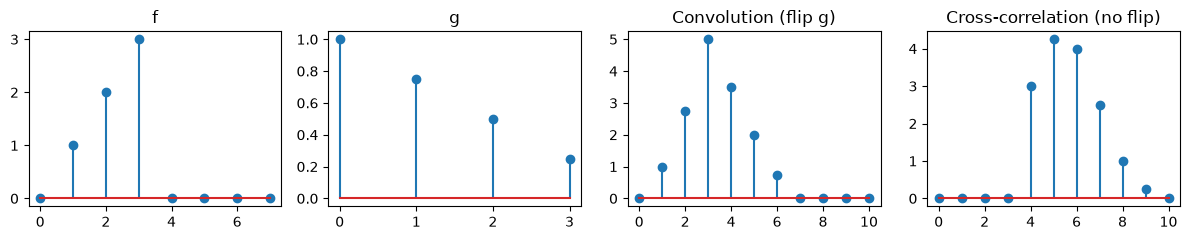

합성곱: [0.   1.   2.75 5.   3.5  2.   0.75 0.   0.   0.   0.  ]
교차상관: [0.   0.   0.   0.   3.   4.25 4.   2.5  1.   0.25 0.  ]
교차상관 == 뒤집은 f와의 합성곱: True


In [ ]:
f = np.array([0, 1, 2, 3, 0, 0, 0, 0], dtype=float)  # 한쪽으로 커지는 신호
g = np.array([1.0, 0.75, 0.5, 0.25])                 # 한쪽으로 작아지는 신호

convolution_1d = np.convolve(f, g)
# np.correlate(a, v)는 a[n + k] * v[n]의 합이다. 위 식과 맞추려면 g를 앞에 둔다
correlation_1d = np.correlate(g, f, mode="full")

fig, axes = plt.subplots(1, 4, figsize=(12, 2.5))
for ax, values, title in zip(
    axes,
    [f, g, convolution_1d, correlation_1d],
    ["f", "g", "Convolution (flip g)", "Cross-correlation (no flip)"],
):
    ax.stem(values)
    ax.set_title(title)
plt.tight_layout()
plt.show()

print("합성곱:", convolution_1d)
print("교차상관:", correlation_1d)
# 교차상관은 한쪽을 뒤집어 합성곱한 것과 같다
print("교차상관 == 뒤집은 f와의 합성곱:", np.allclose(correlation_1d, np.convolve(f[::-1], g)))

두 결과의 값이 다릅니다. 뒤집기 하나로 답이 달라집니다. 마지막 줄처럼 **교차상관은 한쪽 신호를 뒤집어 합성곱한 것과 같습니다**. (신호가 좌우 대칭이면 뒤집어도 그대로이므로 차이가 보이지 않을 수 있습니다. 그래서 비대칭 신호로 그렸습니다.) 이제 합성곱 층에서는 어떤지 봅시다.

**Q. PyTorch의 `nn.Conv2d`는 정말 합성곱일까요?**

코드로 직접 확인합시다. 정의대로 두 가지를 맨손으로 구현해 `nn.Conv2d`, `F.conv2d`와 비교합니다.

In [ ]:
def correlate2d_manual(image: torch.Tensor, kernel: torch.Tensor) -> torch.Tensor:
    """커널을 뒤집지 않고 밀면서 곱해 더합니다(교차상관). 입력은 2차원 텐서입니다."""
    k_h, k_w = kernel.shape
    out_h, out_w = image.shape[0] - k_h + 1, image.shape[1] - k_w + 1
    out = torch.zeros(out_h, out_w)
    for row in range(out_h):
        for col in range(out_w):
            out[row, col] = (image[row : row + k_h, col : col + k_w] * kernel).sum()
    return out


def convolve2d_manual(image: torch.Tensor, kernel: torch.Tensor) -> torch.Tensor:
    """수학적 합성곱입니다. 커널을 상하좌우로 뒤집은 뒤 밉니다."""
    return correlate2d_manual(image, kernel.flip(0, 1))


set_seed()
image = torch.rand(8, 8)
kernel = torch.rand(3, 3)

conv_layer = nn.Conv2d(1, 1, kernel_size=3, bias=False)
conv_layer.weight.data = kernel.view(1, 1, 3, 3)
out_nn = conv_layer(image.view(1, 1, 8, 8))[0, 0].detach()
out_f = F.conv2d(image.view(1, 1, 8, 8), kernel.view(1, 1, 3, 3))[0, 0]

print("nn.Conv2d == F.conv2d    :", torch.allclose(out_nn, out_f))
print("F.conv2d  == 교차상관    :", torch.allclose(out_f, correlate2d_manual(image, kernel)))
print("F.conv2d  == 수학적 합성곱:", torch.allclose(out_f, convolve2d_manual(image, kernel)))

nn.Conv2d == F.conv2d    : True
F.conv2d  == 교차상관    : True
F.conv2d  == 수학적 합성곱: False


<details><summary>답</summary>

`nn.Conv2d`와 `F.conv2d`는 **둘 다 교차상관** 을 계산합니다. 커널을 뒤집지 않습니다. 함수 이름만 보고 `F.conv2d`는 수학적 합성곱이라고 오해하기 쉽지만, 위 실험에서 보듯 아닙니다. `nn.Conv2d`는 내부에서 `F.conv2d`를 호출하므로 둘의 결과가 같습니다.

어쩌면 "cross-correlation neural network"가 맞는 말일지도 모릅니다. 보통은 문제가 없다고 말합니다. 어차피 커널의 값은 학습으로 정해지므로, 뒤집힌 답을 학습하면 그만이기 때문입니다. 그러나 Fourier 변환을 쓰는 CNN처럼 **합성곱의 수학적 정의(합성곱 정리)에 의존해야 하는 경우** 에는 차이가 납니다. 그럴 때는 `kernel.flip`으로 직접 뒤집어 씁니다.

</details>

## 3.3 합성곱 층

합성곱 층은 필터(커널)를 이미지 위로 밀면서 **겹치는 칸끼리 곱해 더합니다**. 아래 그림은 3×3 필터를 입력의 왼쪽 위 3×3 영역(국소 수용 영역, local receptive field)에 적용한 예입니다. ([그림 출처](https://uploads-ssl.webflow.com/614c82ed388d53640613982e/646371e3bdc5ca90dee5331b_convolutional-neural-network%20%281%29.webp), 같은 그림에 LeNet 구조도 있습니다)

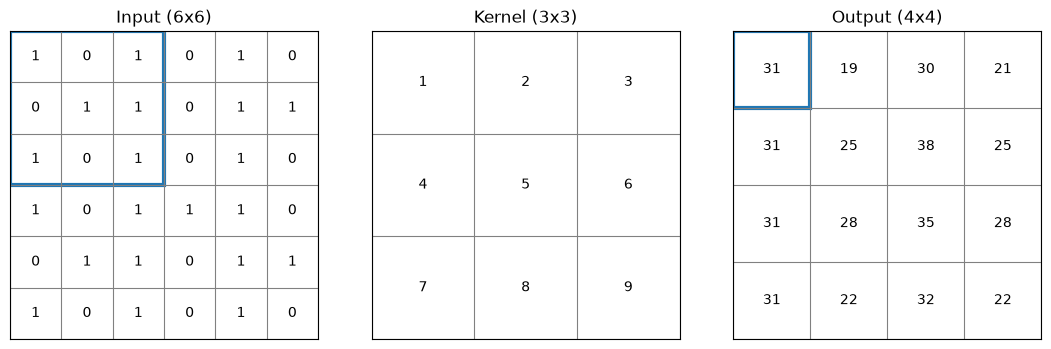

왼쪽 위 칸의 계산: [1, 0, 1, 0, 1, 1, 1, 0, 1] 와 [1, 2, 3, 4, 5, 6, 7, 8, 9] 를 곱해 더하면 31.0


In [ ]:
def draw_grid(
    ax: plt.Axes,
    values: np.ndarray,
    title: str,
    highlight: tuple[int, int, int] | None = None,
    color: str = "tab:blue",
) -> None:
    """숫자가 적힌 격자를 그립니다. highlight는 (행, 열, 크기)로 강조할 사각형입니다."""
    rows, cols = values.shape
    ax.imshow(np.zeros_like(values, dtype=float), cmap="Greys", vmin=0, vmax=1)
    for r in range(rows):
        for c_ in range(cols):
            ax.text(c_, r, f"{values[r, c_]:g}", ha="center", va="center")
    ax.set_xticks(np.arange(-0.5, cols), labels=[])
    ax.set_yticks(np.arange(-0.5, rows), labels=[])
    ax.grid(color="gray")
    ax.tick_params(length=0)
    ax.set_title(title)
    if highlight is not None:
        r, c_, size = highlight
        ax.add_patch(plt.Rectangle((c_ - 0.5, r - 0.5), size, size, fill=False, edgecolor=color, linewidth=3))


grid_input = torch.tensor(
    [[1, 0, 1, 0, 1, 0], [0, 1, 1, 0, 1, 1], [1, 0, 1, 0, 1, 0], [1, 0, 1, 1, 1, 0], [0, 1, 1, 0, 1, 1], [1, 0, 1, 0, 1, 0]],
    dtype=torch.float,
)
grid_kernel = torch.tensor([[1, 2, 3], [4, 5, 6], [7, 8, 9]], dtype=torch.float)
grid_output = F.conv2d(grid_input.view(1, 1, 6, 6), grid_kernel.view(1, 1, 3, 3))[0, 0]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
draw_grid(axes[0], grid_input.numpy(), "Input (6x6)", highlight=(0, 0, 3))
draw_grid(axes[1], grid_kernel.numpy(), "Kernel (3x3)")
draw_grid(axes[2], grid_output.numpy(), "Output (4x4)", highlight=(0, 0, 1))
plt.tight_layout()
plt.show()

first_patch = grid_input[:3, :3]
print("왼쪽 위 칸의 계산:", first_patch.flatten().int().tolist(), "와", grid_kernel.flatten().int().tolist(), "를 곱해 더하면", (first_patch * grid_kernel).sum().item())

필터 하나가 이미지 전체를 지나면 2차원 결과가 하나 나옵니다. 이것을 **특징 지도(activation map, feature map)** 라고 부릅니다. 필터를 여러 개 쓰면 특징 지도도 여러 장 나오고, 이것들이 쌓여 **채널** 이 됩니다. 실제로 학습한 모델의 특징 지도는 3.10절에서 그려 봅니다.

**세 가지 옵션**

1. **stride(스트라이드)**: 필터를 몇 칸씩 움직일 것인가?
2. **padding(패딩)**: 바깥쪽에 값을 덧댈 것인가? 덧대면 가장자리도 충분히 계산되고 크기가 덜 줄어듭니다.
3. **dilation(딜레이션)**: 필터의 칸을 띄엄띄엄 퍼뜨릴 것인가? 파라미터 수는 그대로 두고 더 넓은 영역을 봅니다.

([stride·padding 애니메이션](https://miro.medium.com/v2/resize:fit:792/0*1CwfqZHE9fGu774w.gif) · [dilation 애니메이션](https://cdn-images-1.medium.com/max/497/1*SVkgHoFoiMZkjy54zM_SUw.gif) · [애니메이션 모음: conv_arithmetic](https://github.com/vdumoulin/conv_arithmetic))

아래는 움직임을 정지 그림으로 옮긴 것입니다. 왼쪽은 5×5 입력(진한 칸)에 패딩 1(연한 칸)을 덧대고 3×3 필터를 스트라이드 2로 움직입니다. 필터의 위치 세 곳을 표시했습니다. 오른쪽은 3×3 필터에 딜레이션 2를 준 경우로, 색칠한 9칸만 계산에 씁니다.

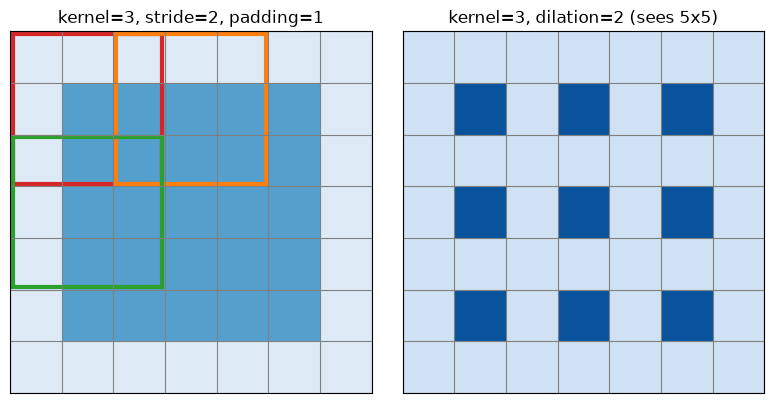

In [ ]:
def draw_stride_padding(ax: plt.Axes) -> None:
    """5x5 입력에 패딩 1, 스트라이드 2인 3x3 필터의 위치를 그립니다."""
    size = 7
    canvas = np.zeros((size, size))
    canvas[1:6, 1:6] = 1  # 원래 입력 영역
    ax.imshow(canvas, cmap="Blues", vmin=-0.3, vmax=2)
    for (r, c_), color in zip([(0, 0), (0, 2), (2, 0)], ["tab:red", "tab:orange", "tab:green"]):
        ax.add_patch(plt.Rectangle((c_ - 0.45, r - 0.45), 2.9, 2.9, fill=False, edgecolor=color, linewidth=3))
    ax.set_xticks(np.arange(-0.5, size), labels=[])
    ax.set_yticks(np.arange(-0.5, size), labels=[])
    ax.grid(color="gray")
    ax.tick_params(length=0)
    ax.set_title("kernel=3, stride=2, padding=1")


def draw_dilation(ax: plt.Axes) -> None:
    """딜레이션 2인 3x3 필터가 쓰는 칸을 그립니다."""
    size = 7
    canvas = np.zeros((size, size))
    canvas[1:6:2, 1:6:2] = 1  # 한 칸씩 건너뛴 9칸
    ax.imshow(canvas, cmap="Blues", vmin=-0.3, vmax=1.2)
    ax.set_xticks(np.arange(-0.5, size), labels=[])
    ax.set_yticks(np.arange(-0.5, size), labels=[])
    ax.grid(color="gray")
    ax.tick_params(length=0)
    ax.set_title("kernel=3, dilation=2 (sees 5x5)")


fig, axes = plt.subplots(1, 2, figsize=(8, 4))
draw_stride_padding(axes[0])
draw_dilation(axes[1])
plt.tight_layout()
plt.show()

출력 크기는 다음 식으로 계산합니다. $n$은 입력 크기, $k$는 커널, $p$는 패딩, $s$는 스트라이드, $d$는 딜레이션입니다.

$$n_{out} = \left\lfloor \frac{n + 2p - d(k-1) - 1}{s} \right\rfloor + 1$$

아래 코드로 확인해 봅시다. 공식 문서: [`nn.Conv2d`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html#torch.nn.Conv2d)

인자는 입력 채널, 출력 채널, 커널 크기, 스트라이드 순입니다. 입력 텐서의 모양은 **(배치, 채널, 높이, 너비)** 입니다. (너비가 앞이 아닙니다.)

In [ ]:
m = nn.Conv2d(16, 33, (3, 5), stride=(2, 1), padding=(4, 2), dilation=(3, 1))
# 입력 채널 16, 출력 채널 33, 커널 3x5, 스트라이드, 패딩, 딜레이션 순이다
input = torch.randn(20, 16, 50, 100)
# 배치 20, 채널 16, 높이 50, 너비 100
output = m(input)
print(input.shape, "->", output.shape)

torch.Size([20, 16, 50, 100]) -> torch.Size([20, 33, 26, 100])


**채널이란 무엇일까요?** RGB만이 채널은 아닙니다.

채널은 표현력입니다. 흑백 사진은 채널이 한 개이고, 컬러 사진은 세 개입니다. 합성곱은 텐서의 정보를 채널 단위로 늘려 줍니다. 필터마다 다른 특징(세로선, 가로선, 곡선...)을 찾으니, 필터가 많을수록 위치별로 더 많은 정보를 담습니다.

위치 정보를 보존하면서 채널로 정보를 늘리고, 풀링이나 스트라이드로 가로세로를 줄입니다(풀링 크기 2면 절반). 이것을 반복하면 **위치 정보가 채널 정보로 압축** 되어 들어가기 시작합니다. 이미지를 넣어 긴 가래떡을 뽑는 것과 비슷합니다.

합성곱이 항상 채널을 늘리고 크기를 줄이는 것은 아닙니다. 위 예에서 너비가 100으로 그대로였듯이, 인자에 따라 정해집니다.

### 필터의 모양

입력이 RGB처럼 여러 채널이면 **필터 하나가 입력 채널 수만큼의 층을 가집니다**. RGB 각각에 대한 커널이 한 장씩 있고, 이 묶음이 출력 채널 수만큼 있습니다. 즉 3채널 입력에서 8채널을 출력하면 커널이 3×8장 있습니다.

In [ ]:
rgb_conv = nn.Conv2d(in_channels=3, out_channels=8, kernel_size=5)
print("가중치 모양 (출력 채널, 입력 채널, 높이, 너비):", rgb_conv.weight.shape)

가중치 모양 (출력 채널, 입력 채널, 높이, 너비): torch.Size([8, 3, 5, 5])


### 합성곱 연산: 객체 방식

`torch.nn` 패키지의 합성곱을 써 봅시다. 이미지를 나타내는 무작위 텐서와 필터를 만들어 적용합니다.

In [ ]:
# (1, 28, 28) 모양의 무작위 이미지 10장
images = torch.rand(10, 1, 28, 28)

# 필터 6개
conv_filters = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=(3, 3), stride=1, padding=1)

# 이미지에 필터를 적용한다
output_feature = conv_filters(images)
print(output_feature.shape)

torch.Size([10, 6, 28, 28])


### 합성곱 연산: 함수 방식

많은 사람이 `torch.nn` 패키지(객체 방식)를 좋아하지만, `torch.nn.functional`로 더 함수형으로 작성하는 사람들도 있습니다. 두 라이브러리를 섞어 써도 됩니다. 같은 일을 함수 방식으로 해 봅시다. 차이는 **필터를 직접 만들어 넘겨야 한다** 는 점입니다. 필터의 모양은 `(출력 채널, 입력 채널, 높이, 너비)`입니다.

In [ ]:
# 무작위 이미지 10장
images = torch.rand(10, 1, 28, 28)

# 필터 6개
filters = torch.rand(6, 1, 3, 3)

# 이미지에 필터를 적용한다
output_feature = F.conv2d(images, filters, stride=1, padding=1)
print(output_feature.shape)

torch.Size([10, 6, 28, 28])


### 실습 3. 출력 크기 계산기

위의 식으로 합성곱 출력 크기를 계산하는 `conv_output_size(n, k, s, p, d)`를 만드세요. 정답의 검증 코드가 실제 `nn.Conv2d`의 결과와 비교합니다.

In [ ]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def conv_output_size(n: int, k: int, s: int = 1, p: int = 0, d: int = 1) -> int:
    return (n + 2 * p - d * (k - 1) - 1) // s + 1


for n_in, k_size, s_size, p_size, d_size in [(28, 3, 1, 1, 1), (28, 3, 2, 1, 1), (50, 3, 2, 4, 3), (100, 11, 4, 0, 1), (7, 5, 2, 2, 2)]:
    layer = nn.Conv2d(1, 1, k_size, stride=s_size, padding=p_size, dilation=d_size)
    real = layer(torch.zeros(1, 1, n_in, n_in)).shape[-1]
    assert conv_output_size(n_in, k_size, s_size, p_size, d_size) == real
print("nn.Conv2d와 모두 일치합니다")
```

</details>

## 3.4 필터는 무엇을 하는가

필터를 직접 만들어 적용해 보면 합성곱이 하는 일이 눈에 보입니다. 먼저 무작위 이미지에 가우시안 필터를 적용합니다. 가운데가 크고 바깥이 작은 필터이므로 주변 픽셀을 섞어 흐리게 만듭니다. 값을 합이 1이 되게 나누지 않았으니 평균이 아니라 **가중합** 이고, 결과 값이 입력보다 커집니다(`imshow`가 범위를 자동으로 맞춰 그림에는 드러나지 않습니다). 평균으로 만들려면 `kernel / kernel.sum()`을 씁니다.

입력과 필터의 모양 순서가 다르니 주의하세요.

- 이미지: `(배치, 채널, 높이, 너비)`
- 필터: `(출력 채널, 입력 채널, 높이, 너비)`

커널의 합: 19.50, 입력 최댓값: 1.00, 결과 최댓값: 12.28


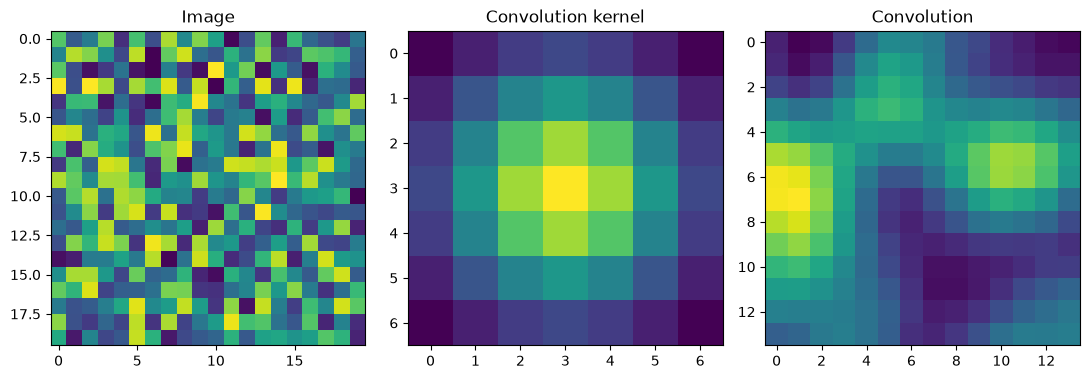

In [ ]:
# 무작위 값으로 만든 20x20 이미지
imgSize = 20
image = torch.rand(imgSize, imgSize)

# 커널은 보통 홀수 크기로 만든다. 가운데 칸이 있어야 하기 때문이다
kernelSize = 7

# 2차원 좌표를 만든다
X_grid, Y_grid = torch.meshgrid(
    torch.linspace(-3, 3, kernelSize), torch.linspace(-3, 3, kernelSize), indexing="ij"
)

# 가우시안의 기본 공식
kernel = torch.exp(-(X_grid ** 2 + Y_grid ** 2) / 7)

# PyTorch가 요구하는 형식으로 바꾼다
image_processed = image.view(1, 1, imgSize, imgSize)
kernel_processed = kernel.view(1, 1, kernelSize, kernelSize)

# 합성곱 적용
convolution = F.conv2d(image_processed, kernel_processed)
print(f"커널의 합: {kernel.sum().item():.2f}, 입력 최댓값: {image.max().item():.2f}, 결과 최댓값: {convolution.max().item():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(11, 4))
ax[0].imshow(image.numpy())
ax[0].set_title("Image")
ax[1].imshow(kernel.numpy())
ax[1].set_title("Convolution kernel")
# Matplotlib이 그릴 수 있도록 2차원으로 되돌린다
ax[2].imshow(convolution.view(convolution.shape[2], convolution.shape[3]).numpy())
ax[2].set_title("Convolution")
plt.tight_layout()
plt.show()

입력이 20×20이었는데 결과는 14×14입니다. 패딩 없이 7×7 필터를 쓰면 가장자리 3칸씩 줄어듭니다.

이번에는 실제 사진으로 세로선과 가로선을 찾아봅시다. `scikit-image`에 들어 있는 고양이 사진 `chelsea`를 씁니다(저작권 없음, CC0).

(300, 451, 3)
torch.Size([300, 451])


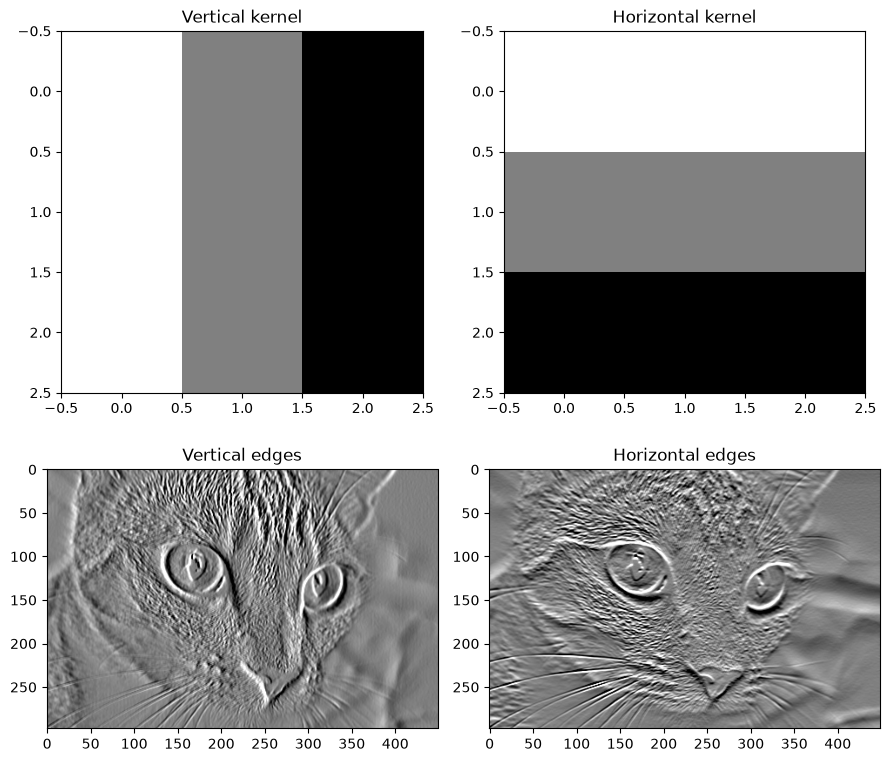

In [ ]:
photo = skimage_data.chelsea()
print(photo.shape)  # (높이, 너비, 채널)

# 편의상 흑백으로 바꾼다. 합성곱 자체에 필요한 일은 아니다
photo = torch.tensor(photo, dtype=torch.float).mean(dim=2)
photo = photo / torch.max(photo)  # 0~1로 스케일링

# 다시 크기 확인
print(photo.shape)

# 세로선을 찾는 필터. 왼쪽과 오른쪽의 차이를 계산한다
VK = torch.tensor([[1.0, 0, -1],
                   [1, 0, -1],
                   [1, 0, -1]]).view(1, 1, 3, 3)  # 필터는 정해진 형식이어야 한다

# 가로선을 찾는 필터. 위쪽과 아래쪽의 차이를 계산한다
HK = torch.tensor([[1.0, 1, 1],
                   [0, 0, 0],
                   [-1, -1, -1]]).view(1, 1, 3, 3)

fig, ax = plt.subplots(2, 2, figsize=(9, 8))

ax[0, 0].imshow(VK.view(3, 3).numpy(), cmap="gray")
ax[0, 0].set_title("Vertical kernel")

ax[0, 1].imshow(HK.view(3, 3).numpy(), cmap="gray")
ax[0, 1].set_title("Horizontal kernel")

# 결과는 양수와 음수가 모두 나온다. 0을 회색으로 두면 경계의 방향까지 보인다
photo_input = photo.view(1, 1, photo.shape[0], photo.shape[1])
EDGE_DISPLAY_RANGE = 0.5
convolution = F.conv2d(photo_input, VK)
ax[1, 0].imshow(convolution[0, 0].numpy(), cmap="gray", vmin=-EDGE_DISPLAY_RANGE, vmax=EDGE_DISPLAY_RANGE)
ax[1, 0].set_title("Vertical edges")

convolution = F.conv2d(photo_input, HK)
ax[1, 1].imshow(convolution[0, 0].numpy(), cmap="gray", vmin=-EDGE_DISPLAY_RANGE, vmax=EDGE_DISPLAY_RANGE)
ax[1, 1].set_title("Horizontal edges")

plt.tight_layout()
plt.show()

왼쪽 결과에서는 세로 방향 경계가, 오른쪽 결과에서는 가로 방향 경계가 밝거나 어둡게 드러납니다. 평평한 곳은 값의 차이가 없어 회색(0)입니다.

CNN은 이런 필터를 사람이 설계하지 않고 **데이터에서 학습** 합니다.

## 3.5 패딩(Padding)

0으로 덧대는 것이 가장 흔하지만, 다른 방법도 있습니다. 공식 문서: [`nn.ZeroPad2d`](https://pytorch.org/docs/stable/generated/torch.nn.ZeroPad2d.html) · [`nn.ReflectionPad1d`](https://pytorch.org/docs/stable/generated/torch.nn.ReflectionPad1d.html)

In [ ]:
m = nn.ZeroPad2d(2)
input = torch.randn(1, 1, 3, 3)
print(input)
print(m(input))

# 면마다 다른 크기로 덧댈 수 있다. 순서는 (왼쪽, 오른쪽, 위, 아래)이다
m = nn.ZeroPad2d((1, 1, 2, 0))
print(m(input))

tensor([[[[-0.9142,  0.5193, -0.5744],
          [ 0.7399,  0.5917, -0.1942],
          [ 0.6347,  0.6112,  1.3576]]]])
tensor([[[[ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
          [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
          [ 0.0000,  0.0000, -0.9142,  0.5193, -0.5744,  0.0000,  0.0000],
          [ 0.0000,  0.0000,  0.7399,  0.5917, -0.1942,  0.0000,  0.0000],
          [ 0.0000,  0.0000,  0.6347,  0.6112,  1.3576,  0.0000,  0.0000],
          [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
          [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000]]]])
tensor([[[[ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
          [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
          [ 0.0000, -0.9142,  0.5193, -0.5744,  0.0000],
          [ 0.0000,  0.7399,  0.5917, -0.1942,  0.0000],
          [ 0.0000,  0.6347,  0.6112,  1.3576,  0.0000]]]])


`ReflectionPad`는 가장자리를 거울처럼 비춰 덧댑니다. 0으로 채우면 가장자리에 인위적인 경계가 생기는데, 이를 줄이고 싶을 때 씁니다.

tensor([[[0., 1., 2., 3.],
         [4., 5., 6., 7.]]])
tensor([[[2., 1., 0., 1., 2., 3., 2., 1.],
         [6., 5., 4., 5., 6., 7., 6., 5.]]])
tensor([[[3., 2., 1., 0., 1., 2., 3., 2.],
         [7., 6., 5., 4., 5., 6., 7., 6.]]])


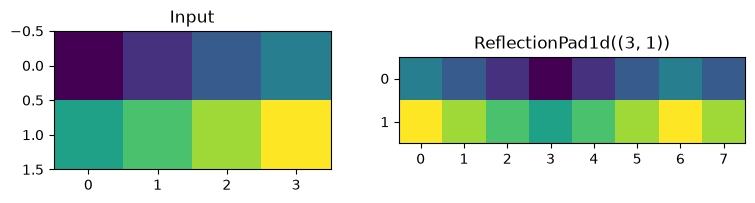

In [ ]:
m = nn.ReflectionPad1d(2)
input = torch.arange(8, dtype=torch.float).reshape(1, 2, 4)
print(input)
print(m(input))

# 면마다 다른 크기로 덧댄다
m = nn.ReflectionPad1d((3, 1))
output = m(input)
print(output)

fig, axes = plt.subplots(1, 2, figsize=(8, 2))
axes[0].imshow(input.squeeze().numpy())
axes[0].set_title("Input")
axes[1].imshow(output.squeeze().numpy())
axes[1].set_title("ReflectionPad1d((3, 1))")
plt.tight_layout()
plt.show()

## 3.6 풀링(Pooling)

입력은 이미지이고, 합성곱으로 채널 정보가 늘어납니다. 그런데 최종 결정을 내리려면 크기를 줄여야 하지 않을까요?

**풀링은 표현을 더 작고 다루기 쉽게** 만듭니다. 채널마다(특징 지도마다) 따로 적용하므로 채널 수는 그대로입니다. 예를 들어 `224×224×64`를 크기 2로 풀링하면 `112×112×64`가 됩니다. ([풀링 그림 출처](https://velog.velcdn.com/images%2Fntk1750%2Fpost%2F923105d8-1649-4bc5-8516-b634cc6284e6%2F20220118_184914_2.png))

1. **Max-pooling**: 영역 안의 최댓값을 고릅니다. ([애니메이션](https://miro.medium.com/v2/resize:fit:1400/1*WvHC5bKyrHa7Wm3ca-pXtg.gif))
2. **Min-pooling**: 영역 안의 최솟값을 고릅니다. PyTorch에 전용 층은 없고 실습에서 직접 만듭니다.
3. **Average-pooling**: 영역 안의 평균을 구합니다. ([애니메이션](https://cdn-images-1.medium.com/max/726/1*fXxDBsJ96FKEtMOa9vNgjA.gif))

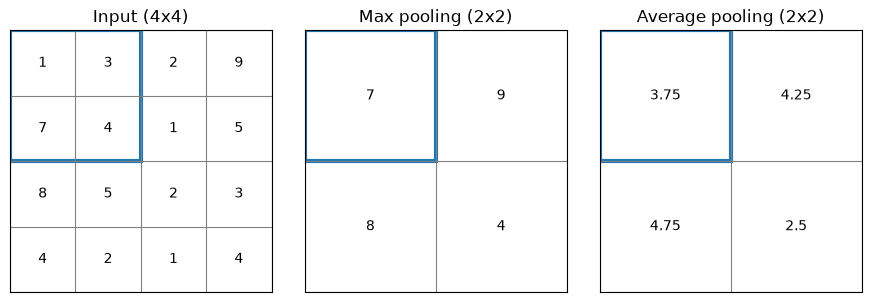

In [ ]:
pool_input = torch.tensor([[1, 3, 2, 9], [7, 4, 1, 5], [8, 5, 2, 3], [4, 2, 1, 4]], dtype=torch.float)
pool_batch = pool_input.view(1, 1, 4, 4)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
draw_grid(axes[0], pool_input.numpy(), "Input (4x4)", highlight=(0, 0, 2))
draw_grid(axes[1], F.max_pool2d(pool_batch, 2)[0, 0].numpy(), "Max pooling (2x2)", highlight=(0, 0, 1))
draw_grid(axes[2], F.avg_pool2d(pool_batch, 2)[0, 0].numpy(), "Average pooling (2x2)", highlight=(0, 0, 1))
plt.tight_layout()
plt.show()

### Max-pooling 연산

객체 방식과 함수 방식 모두로 max-pooling을 해 보고, 결과가 같은지 직접 확인합시다.

In [ ]:
im = torch.rand(1, 1, 6, 6)
im

tensor([[[[0.1877, 0.1523, 0.5211, 0.5516, 0.0417, 0.7558],
          [0.7562, 0.9314, 0.1374, 0.6215, 0.5462, 0.1063],
          [0.7145, 0.4720, 0.3902, 0.8657, 0.8431, 0.6926],
          [0.3766, 0.3925, 0.5658, 0.5618, 0.0487, 0.8149],
          [0.9432, 0.9480, 0.0209, 0.6780, 0.4633, 0.4831],
          [0.3831, 0.7140, 0.2943, 0.3676, 0.0389, 0.3226]]]])

In [ ]:
# 크기 2의 풀링을 만든다
max_pooling = nn.MaxPool2d(2)

# 풀링을 적용한다
output_feature = max_pooling(im)

# 함수 방식으로 적용한다
output_feature_F = F.max_pool2d(im, 2)

# 두 결과를 출력한다
print(output_feature)
print(output_feature_F)

tensor([[[[0.9314, 0.6215, 0.7558],
          [0.7145, 0.8657, 0.8431],
          [0.9480, 0.6780, 0.4831]]]])
tensor([[[[0.9314, 0.6215, 0.7558],
          [0.7145, 0.8657, 0.8431],
          [0.9480, 0.6780, 0.4831]]]])


### Average-pooling 연산

max-pooling을 average-pooling으로 바꾸기만 하면 됩니다.

In [ ]:
# 크기 2의 풀링을 만든다
avg_pooling = nn.AvgPool2d(2)

# 풀링을 적용한다
output_feature = avg_pooling(im)

# 함수 방식으로 적용한다
output_feature_F = F.avg_pool2d(im, 2)

# 두 결과를 출력한다
print(output_feature)
print(output_feature_F)

tensor([[[[0.5069, 0.4579, 0.3625],
          [0.4889, 0.5959, 0.5998],
          [0.7470, 0.3402, 0.3270]]]])
tensor([[[[0.5069, 0.4579, 0.3625],
          [0.4889, 0.5959, 0.5998],
          [0.7470, 0.3402, 0.3270]]]])


풀링 창이 정사각형일 필요는 없습니다. `imshow`는 실수 이미지에서 0~1 범위를 벗어난 값을 잘라 버리고 경고를 내므로, 그려 볼 입력은 `rand`로 만듭니다.

torch.Size([20, 3, 50, 32]) -> torch.Size([20, 3, 24, 16])


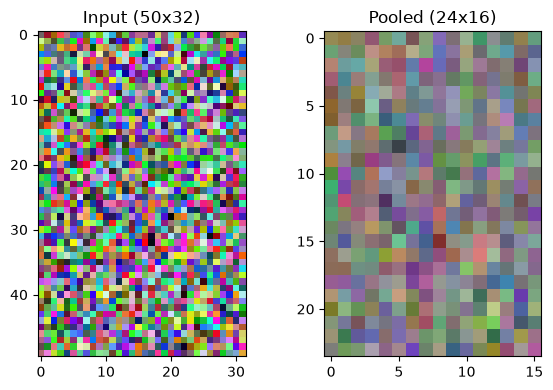

In [ ]:
m = nn.AvgPool2d(3, stride=2)
# 정사각형이 아닌 풀링 창
m = nn.AvgPool2d((3, 2), stride=(2, 2))
input = torch.rand(20, 3, 50, 32)
output = m(input)
print(input.shape, "->", output.shape)

fig, axes = plt.subplots(1, 2, figsize=(6, 4))
axes[0].imshow(input[1].permute(1, 2, 0).numpy())
axes[0].set_title("Input (50x32)")
axes[1].imshow(output[1].permute(1, 2, 0).numpy())
axes[1].set_title("Pooled (24x16)")
plt.tight_layout()
plt.show()

### 실습 4. Min-pooling 만들기

PyTorch에는 `MinPool2d`가 없습니다. `F.max_pool2d`만으로 min-pooling을 구현하세요. (힌트: 부호를 뒤집으면 최솟값이 최댓값이 됩니다.)

In [ ]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def min_pool2d(x: torch.Tensor, kernel_size: int) -> torch.Tensor:
    return -F.max_pool2d(-x, kernel_size)


result = min_pool2d(pool_batch, 2)
expected = torch.tensor([[[[1.0, 1.0], [2.0, 1.0]]]])
assert torch.equal(result, expected)
print(result)
```

</details>

## 3.7 활성화 함수(Activations)

뉴런 하나는 입력에 가중치를 곱해 더하고 절편을 더한 뒤, **활성화 함수** $\varphi$를 통과시킵니다.

$$y = \varphi\left(\sum_{i=1}^{m} w_i x_i + b\right)$$

([뉴런 구조 그림 출처](https://miro.medium.com/v2/resize:fit:640/1*8VSBCaqL2XeSCZQe_BAyVA.jpeg))

활성화 함수가 없으면 층을 아무리 쌓아도 선형 변환 하나와 같습니다. 1강의 XOR에서 본 대로입니다.

활성화 함수는 정말 많습니다. 널리 알려진 18종([정리표 출처](https://miro.medium.com/v2/resize:fit:1400/1*m5vrrbH9VvXPoU3jIf7z9w.jpeg))을 PyTorch로 직접 그려 봅시다.

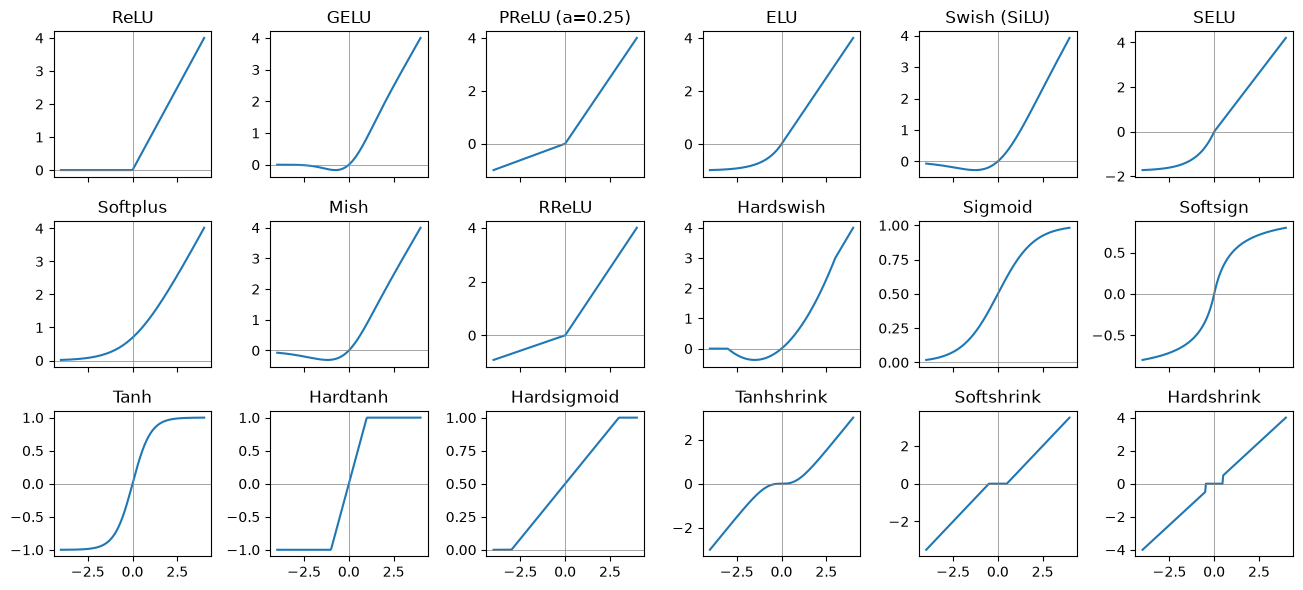

In [ ]:
activation_gallery = {
    "ReLU": F.relu, "GELU": F.gelu, "PReLU (a=0.25)": lambda v: F.prelu(v, torch.tensor(0.25)),
    "ELU": F.elu, "Swish (SiLU)": F.silu, "SELU": F.selu,
    "Softplus": F.softplus, "Mish": F.mish, "RReLU": lambda v: F.rrelu(v, training=False),
    "Hardswish": F.hardswish, "Sigmoid": torch.sigmoid, "Softsign": F.softsign,
    "Tanh": torch.tanh, "Hardtanh": F.hardtanh, "Hardsigmoid": F.hardsigmoid,
    "Tanhshrink": F.tanhshrink, "Softshrink": F.softshrink, "Hardshrink": F.hardshrink,
}

x_axis = torch.linspace(-4, 4, 200)
fig, axes = plt.subplots(3, 6, figsize=(13, 6), sharex=True)
for ax, (name, func) in zip(axes.flatten(), activation_gallery.items()):
    ax.plot(x_axis.numpy(), func(x_axis).numpy())
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvline(0, color="gray", linewidth=0.5)
    ax.set_title(name)
plt.tight_layout()
plt.show()

수식과 설명은 공식 문서에 모여 있습니다: [Non-linear Activations](https://pytorch.org/docs/stable/nn.html#non-linear-activations-weighted-sum-nonlinearity)

입문 단계에서는 은닉층에 ReLU 계열을 먼저 쓰면 됩니다. 시그모이드와 tanh는 양 끝에서 기울기가 0에 가까워져 깊은 신경망에서 학습이 어렵습니다. 자세한 이유는 다음 강의의 기울기 소실에서 다룹니다.

대표적인 함수를 크게 그려 보고 축의 범위도 확인합시다.

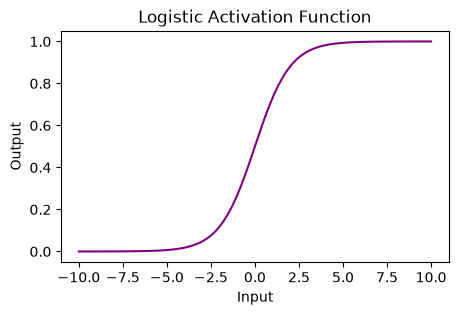

In [ ]:
# 입력 텐서를 만든다
x = torch.linspace(-10, 10, 100)

# 시그모이드(logistic) 활성화 함수를 적용한다
y = torch.sigmoid(x)

plt.figure(figsize=(5, 3))
plt.plot(x.numpy(), y.numpy(), color="purple")
plt.xlabel("Input")
plt.ylabel("Output")
plt.title("Logistic Activation Function")
plt.show()

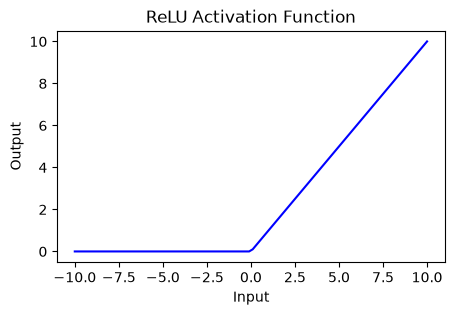

In [ ]:
# 활성화 함수를 시각화한다. 주석을 바꿔 tanh도 그려 보자(그때는 아래 제목도 바꾸세요)
# y = torch.tanh(x)
y = torch.relu(x)

plt.figure(figsize=(5, 3))
plt.plot(x.numpy(), y.numpy(), color="blue")
plt.xlabel("Input")
plt.ylabel("Output")
plt.title("ReLU Activation Function")
plt.show()

**활성화 함수를 바꾸면 학습이 어떻게 달라질까요?** 같은 MLP로 MNIST를 학습해 비교합시다. 입력은 0~1로 바꾼 것을 그대로 씁니다. 전처리는 현재 권장되는 `torchvision.transforms.v2`로 합니다(맨 위 셀에서 `transforms`라는 이름으로 불러왔습니다).

ReLU: 첫 에폭 정확도 95.73%, 마지막 정확도 97.61%, 마지막 테스트 손실 0.0908


Sigmoid: 첫 에폭 정확도 93.09%, 마지막 정확도 97.78%, 마지막 테스트 손실 0.0760


Tanh: 첫 에폭 정확도 95.24%, 마지막 정확도 97.77%, 마지막 테스트 손실 0.0830


LeakyReLU: 첫 에폭 정확도 95.68%, 마지막 정확도 97.85%, 마지막 테스트 손실 0.0838


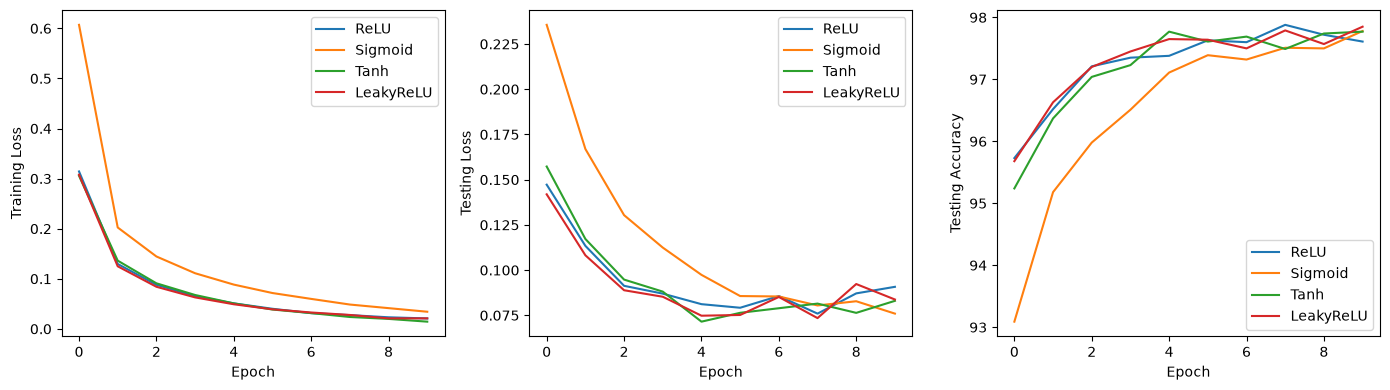

In [ ]:
# 이미지를 0~1 실수 텐서로 바꾼다. ToImage가 텐서로 바꾸고, ToDtype(scale=True)가 0~255를 0~1로 나눈다
transform = transforms.Compose([transforms.ToImage(), transforms.ToDtype(torch.float32, scale=True)])

# MNIST 데이터셋을 불러온다
train_dataset = datasets.MNIST(root="data", train=True, transform=transform, download=True)
test_dataset = datasets.MNIST(root="data", train=False, transform=transform, download=True)

train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)


class NeuralNetwork(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, num_classes: int, activation_function: nn.Module) -> None:
        super().__init__()
        self.layer1 = nn.Linear(input_size, hidden_size)
        self.layer2 = nn.Linear(hidden_size, hidden_size)
        self.layer3 = nn.Linear(hidden_size, num_classes)
        self.activation_function = activation_function

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.activation_function(self.layer1(x))
        x = self.activation_function(self.layer2(x))
        x = self.layer3(x)
        return x


def train(network: nn.Module, data_loader: DataLoader, criterion: nn.Module, optimizer: optim.Optimizer, device: torch.device) -> float:
    network.train()
    running_loss = 0.0

    for data, target in data_loader:
        data, target = data.to(device), target.to(device)
        data = data.view(data.shape[0], -1)

        optimizer.zero_grad()
        output = network(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * data.size(0)

    return running_loss / len(data_loader.dataset)


def test(network: nn.Module, data_loader: DataLoader, criterion: nn.Module, device: torch.device) -> tuple[float, float]:
    network.eval()
    correct = 0
    total = 0
    test_loss = 0.0

    with torch.no_grad():
        for data, target in data_loader:
            data, target = data.to(device), target.to(device)
            data = data.view(data.shape[0], -1)

            output = network(data)
            loss = criterion(output, target)
            test_loss += loss.item() * data.size(0)
            _, predicted = torch.max(output, 1)
            total += target.size(0)
            correct += (predicted == target).sum().item()

    return test_loss / len(data_loader.dataset), 100 * correct / total


input_size = 784
hidden_size = 128
num_classes = 10
num_epochs = 10
learning_rate = 0.001

activation_functions = {
    "ReLU": nn.ReLU(),
    "Sigmoid": nn.Sigmoid(),
    "Tanh": nn.Tanh(),
    "LeakyReLU": nn.LeakyReLU(),
}

results = {}

# 활성화 함수를 바꿔 가며 같은 조건으로 학습한다
for name, activation_function in activation_functions.items():
    set_seed()  # 초기값 차이가 비교를 흐리지 않도록 함수마다 시드를 다시 고정한다
    model = NeuralNetwork(input_size, hidden_size, num_classes, activation_function).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    train_loss_history = []
    test_loss_history = []
    test_accuracy_history = []

    for epoch in range(num_epochs):
        train_loss = train(model, train_loader, criterion, optimizer, device)
        test_loss, test_accuracy = test(model, test_loader, criterion, device)

        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        test_accuracy_history.append(test_accuracy)

    print(f"{name}: 첫 에폭 정확도 {test_accuracy_history[0]:.2f}%, 마지막 정확도 {test_accuracy_history[-1]:.2f}%, 마지막 테스트 손실 {test_loss_history[-1]:.4f}")

    results[name] = {
        "train_loss_history": train_loss_history,
        "test_loss_history": test_loss_history,
        "test_accuracy_history": test_accuracy_history,
    }

# 세 그래프를 한 줄에 그린다
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, key, label in zip(
    axes,
    ["train_loss_history", "test_loss_history", "test_accuracy_history"],
    ["Training Loss", "Testing Loss", "Testing Accuracy"],
):
    for name, data in results.items():
        ax.plot(data[key], label=name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(label)
    ax.legend()
plt.tight_layout()
plt.show()

저장된 출력을 읽어 봅시다. 첫 에폭에서는 시그모이드가 가장 뒤처집니다(93.09%, ReLU는 95.73%). 학습 손실 곡선도 시그모이드만 위에서 시작합니다. 그러나 10 에폭 뒤의 정확도는 네 함수 모두 97.6~97.9%로 차이가 없습니다.

앞에서 "시그모이드는 깊은 신경망에서 학습이 어렵다"고 했는데, 여기서는 은닉층이 **2개뿐** 이라 그 문제가 드러나지 않고 출발이 느린 정도로 나타납니다. 시드 하나로 잰 0.2%포인트 차이로 순위를 매기지 마세요. 시그모이드를 뺀 세 함수는 학습 손실이 계속 줄어드는데 테스트 손실은 5 에폭 무렵부터 더 내려가지 않습니다. 과적합이 시작됐다는 신호입니다. 은닉층을 늘리면 어떻게 달라지는지는 숙제 2에서 직접 확인하세요.

## 3.8 2교시의 `fit`으로 CNN 학습하기

이제 합성곱을 배웠으니 2교시의 리팩터링을 마저 이어 갑니다. 3개의 합성곱 층으로 신경망을 만듭니다. 앞에서 만든 함수는 어느 것도 모델의 형식을 가정하지 않으므로, **별도의 수정 없이** CNN 학습에 쓸 수 있습니다.

PyTorch의 [Conv2d](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)를 합성곱 층으로 씁니다. 각 합성곱 뒤에는 ReLU가 있고, 마지막에 평균 풀링을 합니다. `view`는 NumPy `reshape`의 PyTorch 판입니다.

크기 변화를 따라가 봅시다. 스트라이드 2로 절반씩 줄어듭니다: 28 → 14 → 7 → 4. 마지막 합성곱의 출력 채널이 10이므로, `4×4×10`을 평균 풀링으로 `1×1×10`으로 만들면 10개 클래스의 점수가 됩니다. 완전 연결 층이 하나도 없습니다.

In [ ]:
class Mnist_CNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1)
        self.conv2 = nn.Conv2d(16, 16, kernel_size=3, stride=2, padding=1)
        self.conv3 = nn.Conv2d(16, 10, kernel_size=3, stride=2, padding=1)

    def forward(self, xb: torch.Tensor) -> torch.Tensor:
        xb = xb.view(-1, 1, 28, 28)
        xb = F.relu(self.conv1(xb))
        xb = F.relu(self.conv2(xb))
        xb = F.relu(self.conv3(xb))
        xb = F.avg_pool2d(xb, 4)
        return xb.view(-1, xb.size(1))


lr = 0.1

[모멘텀(Momentum)](https://cs231n.github.io/neural-networks-3/#sgd)은 2강에서 본 대로, 이전 업데이트도 고려해 보통 더 빠른 학습으로 이어지는 SGD의 변형입니다.

In [ ]:
set_seed()
model = Mnist_CNN()
opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

fit(epochs, model, loss_func, opt, train_dl, valid_dl)

0 0.3677243693113327


1 0.21051675542593


### `nn.Sequential`

`Sequential`을 쓰면 `forward`를 따로 쓰지 않아도 됩니다. 다만 `view`처럼 층이 아닌 연산은 넣을 수 없으니, 함수를 층으로 감싸는 `Lambda`를 직접 만듭니다.

In [ ]:
class Lambda(nn.Module):
    def __init__(self, func: Callable[[torch.Tensor], torch.Tensor]) -> None:
        super().__init__()
        self.func = func

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.func(x)


def preprocess(x: torch.Tensor) -> torch.Tensor:
    return x.view(-1, 1, 28, 28)

`Sequential`로 만든 모델은 이렇게 간단합니다.

In [ ]:
set_seed()
model = nn.Sequential(
    Lambda(preprocess),
    nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 10, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.AvgPool2d(4),
    Lambda(lambda x: x.view(x.size(0), -1)),
)

opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

fit(epochs, model, loss_func, opt, train_dl, valid_dl)

0 0.3677243693113327


1 0.21051675542593


위의 `Mnist_CNN` 결과와 손실이 똑같습니다. 층의 구성과 시드가 같으면 같은 모델이라는 뜻입니다. 코드만 짧아졌습니다.

### GPU 사용하기

CUDA를 지원하는 GPU를 쓸 수 있으면 코드 실행 속도를 높일 수 있습니다. Colab에서는 `런타임 유형 변경`에서 GPU를 고르면 됩니다. 먼저 GPU가 PyTorch에서 작동하는지 확인합니다. (Apple Silicon Mac이라면 `mps`입니다.)

In [ ]:
print(torch.cuda.is_available(), torch.backends.mps.is_available())

False True


그리고 디바이스 객체를 만듭니다. 맨 위 셀에서 만든 `device`와 같은 것입니다.

In [ ]:
dev = device
print(dev)

mps


**모델만 옮기고 데이터를 안 옮기면 어떻게 될까요?** GPU를 처음 쓸 때 가장 자주 만나는 에러입니다. CUDA에서는 `Input type (torch.FloatTensor) and weight type (torch.cuda.FloatTensor) should be the same`처럼 나옵니다. 모델은 GPU에 있는데 입력은 CPU에 있다는 뜻입니다. 일부러 재현해 봅시다.

In [ ]:
try:
    model.to(dev)
    model(x_valid[:2])  # 입력은 아직 CPU에 있다
    print("GPU가 없는 환경이라 모델과 입력이 모두 CPU에 있어 에러가 나지 않습니다")
except RuntimeError as error:
    print("RuntimeError:", str(error)[:150])

RuntimeError: slow_conv2d_forward_mps: input(device='cpu') and weight(device=mps:0')  must be on the same device


**모델과 데이터는 같은 장치에 있어야 합니다.** 데이터도 옮깁시다.

배치 모양을 바꾸는 `preprocess`를 `DataLoader`를 감싸는 쪽으로 옮겨 봅니다. 이렇게 하면 모델은 이미지 크기를 몰라도 됩니다. 이름은 같지만 인자가 `(x, y)`인 새 함수이고, 위의 `Sequential` 안에 든 `Lambda`는 이전 함수를 그대로 들고 있으므로 영향이 없습니다.

In [ ]:
def preprocess(x: torch.Tensor, y: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    return x.view(-1, 1, 28, 28), y


class WrappedDataLoader:
    def __init__(
        self,
        dl: DataLoader,
        func: Callable[[torch.Tensor, torch.Tensor], tuple[torch.Tensor, torch.Tensor]],
    ) -> None:
        self.dl = dl
        self.func = func

    def __len__(self) -> int:
        return len(self.dl)

    def __iter__(self):
        batches = iter(self.dl)
        for b in batches:
            yield self.func(*b)


# 여기서 데이터를 통째로 GPU에 올린다. 앞의 에러가 나지 않는 이유다
train_ds = TensorDataset(x_train.to(dev), y_train.to(dev))
valid_ds = TensorDataset(x_valid.to(dev), y_valid.to(dev))

train_dl, valid_dl = get_data(train_ds, valid_ds, bs)

train_dl = WrappedDataLoader(train_dl, preprocess)
valid_dl = WrappedDataLoader(valid_dl, preprocess)

마지막으로 모델을 GPU로 옮깁니다. 옵티마이저는 **모델을 옮긴 뒤에** 만듭니다.

In [ ]:
model.to(dev)
opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

이제 GPU에서 실행됩니다. 모델을 새로 만들지 않았으므로 앞의 학습에 **이어서** 학습합니다. 손실이 앞보다 낮은 이유입니다. 이 정도로 작은 모델은 GPU의 이득이 크지 않을 수 있습니다. 차이는 큰 모델에서 드러납니다.

In [ ]:
fit(epochs, model, loss_func, opt, train_dl, valid_dl)

0 0.18278641175031662


1 0.169223108959198


데이터를 GPU에 통째로 올리는 방식은 MNIST처럼 작은 데이터에서나 가능합니다. 데이터가 크면 학습 루프 안에서 **배치마다** `xb.to(device)`로 옮깁니다. 3.7절의 `train` 함수가 그렇게 합니다.

## 3.9 역사적인 모델 살펴보기: AlexNet

> AlexNet은 2012년에 개최된 ILSVRC(ImageNet Large Scale Visual Recognition Challenge) 대회에서 우승을 차지한 합성곱 신경망입니다. CNN의 부흥에 아주 큰 역할을 한 구조입니다.

([구조 그림 출처](https://raw.githubusercontent.com/Masterx-AI/AlexNet-Implementation/main/AlexNet.png))

그림은 작은 입력과 10개 클래스에 맞춘 변형입니다. `conv1`(64채널) → 풀링 → `conv2`(192채널) → 풀링 → `conv3_1~3`(384, 256, 256채널) → 풀링 → 완전 연결 `fc4`, `fc5`(4096) → `fc6`+softmax(10)이고, 공간 크기는 16에서 8, 4로 줄어듭니다. 3.1절에서 본 "특징 학습 + 분류" 구조 그대로입니다. 채널은 늘다가 마지막에 256으로 줄어듭니다.

아래 코드는 구조는 같지만 ImageNet 크기인 **224×224×3 입력과 1000개 클래스** 를 씁니다. 이름은 `conv3_1~3`이 `conv3`, `conv4`, `conv5`이고 `fc4~6`이 `fc1~3`입니다. 채널 수 64, 192, 384, 256, 256은 `torchvision`의 AlexNet과 같습니다. [원 논문](https://proceedings.neurips.cc/paper_files/paper/2012/file/c399862d3b9d6b76c8436e924a68c45b-Paper.pdf)은 96, 256, 384, 384, 256채널이고, Dropout과 Local Response Normalization도 있습니다. 아래는 그 둘을 뺀 단순화 버전입니다.

처음 보는 것이 두 가지 있습니다.

- `nn.AdaptiveAvgPool2d((6, 6))`: 창 크기 대신 **출력 크기** 를 정하는 풀링입니다. 입력 크기가 달라도 항상 6×6이 나오므로 뒤의 완전 연결 층이 깨지지 않습니다. 224×224 입력에서는 이미 6×6이라 값이 바뀌지 않습니다.
- `nn.ReLU(inplace=True)`: 입력 텐서를 덮어써 메모리를 아낍니다. 계산 결과는 같습니다.

In [ ]:
class AlexNet(nn.Module):
    def __init__(self, num_classes: int = 1000) -> None:
        super().__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=11, stride=4, padding=2)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2)
        self.conv2 = nn.Conv2d(64, 192, kernel_size=5, padding=2)
        self.conv3 = nn.Conv2d(192, 384, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(384, 256, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.avgpool = nn.AdaptiveAvgPool2d((6, 6))
        self.fc1 = nn.Linear(256 * 6 * 6, 4096)
        self.fc2 = nn.Linear(4096, 4096)
        self.fc3 = nn.Linear(4096, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.relu(self.conv1(x))
        x = self.maxpool(x)
        x = self.relu(self.conv2(x))
        x = self.maxpool(x)
        x = self.relu(self.conv3(x))
        x = self.relu(self.conv4(x))
        x = self.relu(self.conv5(x))
        x = self.maxpool(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), 256 * 6 * 6)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)


# 층별 출력 모양과 파라미터 수를 확인한다. 2강에서 본 torchinfo다
print(summary(AlexNet(), input_size=(1, 3, 224, 224), depth=1, col_names=["output_size", "num_params"], verbose=0))

Layer (type:depth-idx)                   Output Shape              Param #
AlexNet                                  [1, 1000]                 --
├─Conv2d: 1-1                            [1, 64, 55, 55]           23,296
├─ReLU: 1-2                              [1, 64, 55, 55]           --
├─MaxPool2d: 1-3                         [1, 64, 27, 27]           --
├─Conv2d: 1-4                            [1, 192, 27, 27]          307,392
├─ReLU: 1-5                              [1, 192, 27, 27]          --
├─MaxPool2d: 1-6                         [1, 192, 13, 13]          --
├─Conv2d: 1-7                            [1, 384, 13, 13]          663,936
├─ReLU: 1-8                              [1, 384, 13, 13]          --
├─Conv2d: 1-9                            [1, 256, 13, 13]          884,992
├─ReLU: 1-10                             [1, 256, 13, 13]          --
├─Conv2d: 1-11                           [1, 256, 13, 13]          590,080
├─ReLU: 1-12                             [1, 256, 13, 13]    

어느 층에 파라미터가 몰려 있는지 살펴보세요. 합성곱 층보다 완전 연결 층이 훨씬 많습니다. 3.1절의 이야기가 그대로 드러납니다.

## 3.10 만들어 보자

합성곱 2개, ReLU, 풀링, 완전 연결 1개로 MNIST 분류기를 직접 만듭니다. 크기를 따라가 봅시다. 28 → (풀링) 14 → (풀링) 7이고 채널이 10이므로 완전 연결 층의 입력은 $7 \times 7 \times 10 = 490$입니다.

In [ ]:
class Net(nn.Module):
    def __init__(self) -> None:
        super().__init__()

        # 합성곱 층 2개
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=5, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=5, out_channels=10, kernel_size=3, padding=1)

        # ReLU 비선형 함수
        self.relu = nn.ReLU(inplace=True)

        # max pooling 층
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # 완전 연결 층
        self.fc = nn.Linear(49 * 10, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # 합성곱 다음 ReLU, 그다음 풀링
        x = self.relu(self.conv1(x))
        x = self.pool(x)

        # 합성곱 다음 ReLU, 그다음 풀링
        x = self.relu(self.conv2(x))
        x = self.pool(x)

        # 완전 연결 층에 넣기 위해 펼친다
        x = x.view(-1, 7 * 7 * 10)

        # 완전 연결 층을 적용하고 결과를 돌려준다
        return self.fc(x)

데이터를 준비합니다. `Normalize`의 0.1307과 0.3081은 MNIST 학습 데이터의 평균과 표준편차로 널리 쓰이는 값입니다. 배치 크기 1은 샘플 하나마다 가중치를 고치는 방식입니다(온라인 학습). 옵티마이저는 아래처럼 SGD가 아니라 Adam을 쓰니 혼동하지 마세요. "배치 크기"와 "옵티마이저"는 따로 고르는 것입니다. 한 번에 한 장씩 처리해 GPU의 병렬 계산 이점이 없으므로 이 모델은 CPU에서 학습합니다. 1 에폭에 6만 번 갱신합니다.

In [ ]:
# 텐서로 바꾸고 정규화한다
transform = transforms.Compose([
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize((0.1307,), (0.3081,)),
])

# 학습 세트와 테스트 세트를 준비한다
trainset = datasets.MNIST("data", train=True, transform=transform, download=True)
testset = datasets.MNIST("data", train=False, transform=transform, download=True)

# 로더를 준비한다
# 3.7절의 train_loader(배치 64)를 덮어쓰지 않도록 이름을 나눈다
single_train_loader = DataLoader(trainset, batch_size=1, shuffle=True, num_workers=0)
single_test_loader = DataLoader(testset, batch_size=1, shuffle=False, num_workers=0)

In [ ]:
set_seed()
net = Net()
optimizer = optim.Adam(net.parameters(), lr=3e-4)
criterion = nn.CrossEntropyLoss()

In [ ]:
for i, data in enumerate(single_train_loader, 0):
    inputs, labels = data
    optimizer.zero_grad()

    # 순전파
    outputs = net(inputs)

    # 손실 계산
    loss = criterion(outputs, labels)

    # 기울기 계산
    loss.backward()

    # 가중치 갱신
    optimizer.step()

In [ ]:
net.eval()
with torch.no_grad():
    # 테스트 데이터를 하나씩 본다
    for i, data in enumerate(single_test_loader):
        # 이미지와 레이블을 꺼낸다
        image, label = data

        # 순전파
        output = net(image)

        # 점수가 가장 큰 클래스를 고른다
        _, predicted = torch.max(output, 1)

        if predicted == label:
            print("Yipes, your net made the right prediction " + str(predicted))
        else:
            print("Your net prediction was " + str(predicted) + ", but the correct label is: " + str(label))

        if i > 10:
            break

Yipes, your net made the right prediction tensor([7])
Yipes, your net made the right prediction tensor([2])
Yipes, your net made the right prediction tensor([1])
Yipes, your net made the right prediction tensor([0])
Yipes, your net made the right prediction tensor([4])
Yipes, your net made the right prediction tensor([1])
Yipes, your net made the right prediction tensor([4])
Yipes, your net made the right prediction tensor([9])
Yipes, your net made the right prediction tensor([5])
Yipes, your net made the right prediction tensor([9])
Yipes, your net made the right prediction tensor([0])
Yipes, your net made the right prediction tensor([6])


12장으로는 성능을 말할 수 없습니다. 테스트 세트 전체로 재 봅시다.

In [ ]:
correct = 0
with torch.no_grad():
    for image, label in DataLoader(testset, batch_size=256):
        correct += (net(image).argmax(dim=1) == label).sum().item()
print(f"테스트 정확도: {100 * correct / len(testset):.2f}%")

테스트 정확도: 97.57%


### 특징 지도 그려 보기

3.3절에서 말한 특징 지도(activation map)를 학습된 모델에서 직접 꺼내 봅시다. 윗줄은 첫 합성곱 층의 필터 5개 전부를, 아랫줄은 둘째 합성곱 층의 필터 10개 중 앞의 5개를 숫자 이미지에 적용한 결과입니다.

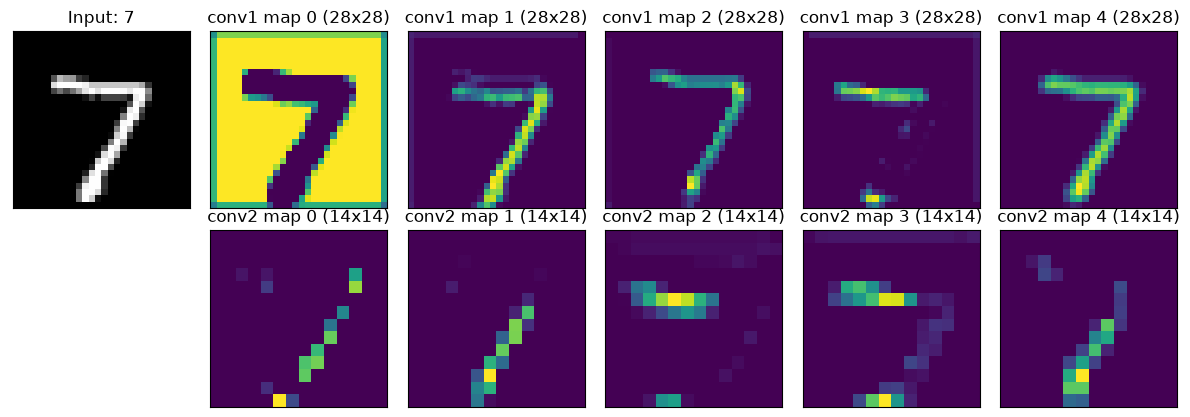

In [ ]:
digit, digit_label = testset[0]
with torch.no_grad():
    maps_first = net.relu(net.conv1(digit.unsqueeze(0)))[0]
    maps_second = net.relu(net.conv2(net.pool(maps_first.unsqueeze(0))))[0]

fig, axes = plt.subplots(2, 6, figsize=(12, 4.2))
axes[0, 0].imshow(digit[0].numpy(), cmap="gray")
axes[0, 0].set_title(f"Input: {digit_label}")
axes[1, 0].axis("off")
for j in range(5):
    axes[0, j + 1].imshow(maps_first[j].numpy(), cmap="viridis")
    axes[0, j + 1].set_title(f"conv1 map {j} (28x28)")
    axes[1, j + 1].imshow(maps_second[j].numpy(), cmap="viridis")
    axes[1, j + 1].set_title(f"conv2 map {j} (14x14)")
for ax in axes.flatten():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

같은 숫자를 필터마다 다른 방식으로 강조합니다. 층이 깊어지면 해상도는 낮아지고, 사람 눈으로 해석하기는 어려워집니다.

## 3.11 현재의 CNN

AlexNet과 앞의 모델은 원리를 배우기 좋은 구조입니다. 실제 문제에서 무엇을 먼저 쓸지는 다음과 같습니다.

- **처음부터 설계하기보다 사전학습 모델을 가져와 전이학습** 합니다. 데이터가 적어도 잘 됩니다. 방법은 5강에서 배웁니다.
- 합성곱 계열의 대표는 잔차 연결과 BatchNorm을 쓰는 **ResNet**, 그리고 Transformer의 설계를 받아들인 **ConvNeXt** 입니다.
- 거대한 완전 연결 층 대신 **전역 평균 풀링**(`nn.AdaptiveAvgPool2d(1)`)으로 공간 차원을 없앱니다. 3.8절의 `Mnist_CNN`이 맛본 방식입니다. 파라미터가 크게 줄어듭니다.

아래처럼 세 모델의 파라미터 수를 비교해 봅시다. `weights=None`이라 사전학습 가중치를 내려받지 않습니다.

코드를 짤 때도 두 가지를 알아 두세요. 3.8절에서 직접 만든 `Lambda` 없이 `nn.Unflatten`과 `nn.Flatten`으로 같은 `Sequential`을 쓸 수 있고, 스트라이드 1에서 크기를 유지하려면 패딩을 계산하지 않고 `padding="same"`이라고 쓰면 됩니다.

In [ ]:
for model_name in ["alexnet", "resnet18", "convnext_tiny"]:
    reference_model = getattr(torchvision.models, model_name)(weights=None)
    print(f"{model_name:15s} 파라미터 {count_params(reference_model) / 1e6:.1f}M")

# Lambda 없이 쓰는 3.8절의 Sequential. 출력 모양이 [배치, 10]으로 같다
modern_cnn = nn.Sequential(
    nn.Unflatten(1, (1, 28, 28)),
    nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 10, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
)
print(modern_cnn(torch.zeros(4, 784)).shape)

# padding="same"은 스트라이드 1에서 크기를 유지한다
print(nn.Conv2d(1, 8, kernel_size=3, padding="same")(torch.zeros(1, 1, 28, 28)).shape)

alexnet         파라미터 61.1M


resnet18        파라미터 11.7M


convnext_tiny   파라미터 28.6M
torch.Size([4, 10])
torch.Size([1, 8, 28, 28])


### 실습 5. CNN 구조 바꿔 보기

`Net`을 본떠, 합성곱을 3개로 늘린 `DeepNet`을 만드세요. 조건은 다음과 같습니다.

- 합성곱 채널: 1 → 8 → 16 → 32, 모두 `kernel_size=3, padding=1`
- 앞의 두 합성곱 뒤에만 `MaxPool2d(2)`
- 마지막에 완전 연결 층 하나로 10개 클래스 출력

완전 연결 층의 입력 크기는 직접 계산하세요. 맞으면 28×28 입력에서 `[배치, 10]`이 나옵니다.

In [ ]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
class DeepNet(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 28 -> 14
            nn.Conv2d(8, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 14 -> 7
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),                  # 7 유지
        )
        self.fc = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        return self.fc(x.flatten(1))


deep_out = DeepNet()(torch.zeros(4, 1, 28, 28))
assert deep_out.shape == (4, 10)
print(deep_out.shape)
```

</details>

---
# 4교시. Siamese Network

지금까지는 "이 사진이 어느 클래스인가"를 맞혔습니다. 그런데 사람 얼굴처럼 클래스가 계속 늘어나는 문제라면 어떨까요? 새로운 사람이 올 때마다 다시 학습할 수는 없습니다.

**두 장의 사진을 비교하는 건 어떨까요?** "같은 사람인가, 다른 사람인가"만 배우면 처음 보는 사람도 다룰 수 있습니다.

1. **임베딩**: 이미지를 벡터로 바꿉니다.
2. **비교**: 두 벡터의 거리를 잽니다.
3. **학습**: 같은 것은 가깝게, 다른 것은 멀게 만듭니다.

## 4.1 구조와 손실 함수

핵심은 **같은 신경망을 두 번 쓴다** 는 것입니다. 그림으로 흔히 쌍둥이 신경망 두 개를 그리지만, 가중치를 공유하므로 실제로는 하나입니다. ([구조 그림: 서명 비교 예](https://miro.medium.com/v2/resize:fit:1400/1*0E9104t29iMBmtvq7G1G6Q.png) · [임베딩 그림: MathWorks](https://kr.mathworks.com/help/examples/nnet/win64/TrainASiameseNetworkForDimensionalityReductionExample_03.png))

```text
이미지 A ─→ [ CNN ] ─→ 벡터 a ─┐
              │ 가중치 공유      ├─→ 거리 D ─→ Contrastive Loss
이미지 B ─→ [ CNN ] ─→ 벡터 b ─┘
```

서명 비교 그림도 같은 구조입니다. 서명 두 장이 각각 "Siamese Network 1"과 "Siamese Network 2"로 들어가고, 둘 사이에 가중치가 오가며(Flow of weights), 결과가 Contrastive Loss로 모입니다.

### Contrastive loss

$$L = Y \cdot D^2 + (1-Y) \cdot \max(m - D,\ 0)^2$$

- 같으면($Y=1$): $D$가 줄어들어야 합니다.
- 다르면($Y=0$): $\max(m-D, 0)$이 줄어들어야 합니다. 즉 $D$가 늘어나야 합니다. 단, $m$보다 커지면 손실이 0이라 더 벌릴 이유가 없습니다.

([수식 그림과 예시 출처](https://b2633864.smushcdn.com/2633864/wp-content/uploads/2021/01/contrastive_loss_keras_header_updated.png?lossy=2&strip=1&webp=1): 같은 숫자 0 두 장은 거리가 0.03~0.15로 작고, 다른 숫자 쌍은 0.59로 큽니다.)

> **주의**: 레이블의 의미는 구현마다 다릅니다. 위 식은 같을 때 $Y=1$이지만, 아래 AT&T 예제의 코드는 **다를 때 레이블이 1**(같을 때 0)입니다. 그래서 코드의 식은 $(1-Y) D^2 + Y \max(m-D, 0)^2$로, 두 항의 위치가 바뀌어 있습니다. 내용은 같습니다.

**Q. 절대 거리에 대한 기준이 애매합니다. 마진의 길이는 어떻게 정할까요?**

<details><summary>답</summary>

정답이 있는 값이 아닙니다. 임베딩의 크기에 따라 의미가 달라지므로 실험으로 정하는 하이퍼파라미터입니다. 임베딩을 단위 길이로 정규화하면 거리의 범위가 0~2로 고정되어 정하기 쉬워집니다. 이 애매함을 피하려고 나온 것이 아래의 Triplet loss입니다. 절대 거리 대신 **상대 거리** 를 학습합니다.

</details>

### Triplet loss

이미지 세 장을 씁니다. 기준(anchor), 같은 대상(positive), 다른 대상(negative)입니다. ([그림 출처](https://miro.medium.com/v2/resize:fit:1400/1*MIPdyhJGx6uLiob9UI9S0w.png))

- positive 쌍의 거리: $d_p = d(f(x_a), f(x_p))$
- negative 쌍의 거리: $d_n = d(f(x_a), f(x_n))$
- 손실: $L = \max(0,\ d_p - d_n + \alpha)$

> 상대 거리 자체를 학습합니다. 여기서 마진 $\alpha$는 두 거리의 차이를 더 벌리기 위한 것입니다. 손실이 0이 되려면 $d_p + \alpha < d_n$을 만족해야 합니다.

두 손실의 모양을 그려 봅시다.

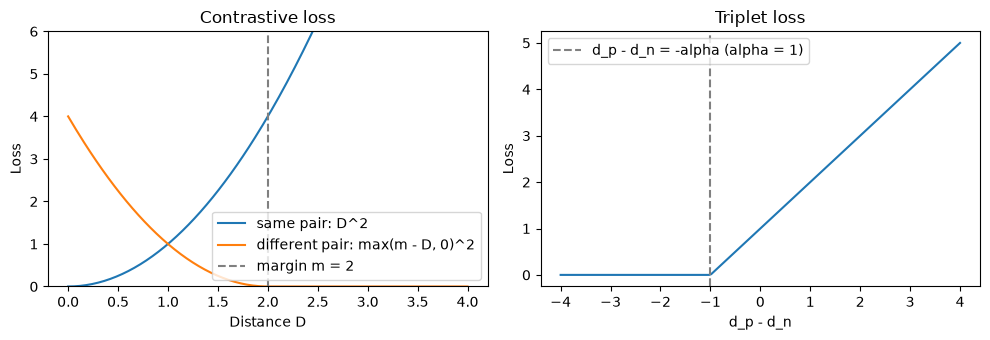

In [ ]:
LOSS_MARGIN = 2.0
distance = torch.linspace(0, 4, 200)
same_loss = distance ** 2
different_loss = torch.clamp(LOSS_MARGIN - distance, min=0) ** 2
gap = torch.linspace(-4, 4, 200)  # d_p - d_n
triplet_loss_curve = torch.clamp(gap + 1.0, min=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(distance.numpy(), same_loss.numpy(), label="same pair: D^2")
axes[0].plot(distance.numpy(), different_loss.numpy(), label="different pair: max(m - D, 0)^2")
axes[0].axvline(LOSS_MARGIN, color="gray", linestyle="--", label="margin m = 2")
axes[0].set_ylim(0, 6)
axes[0].set_xlabel("Distance D")
axes[0].set_ylabel("Loss")
axes[0].set_title("Contrastive loss")
axes[0].legend()
axes[1].plot(gap.numpy(), triplet_loss_curve.numpy())
axes[1].axvline(-1.0, color="gray", linestyle="--", label="d_p - d_n = -alpha (alpha = 1)")
axes[1].set_xlabel("d_p - d_n")
axes[1].set_ylabel("Loss")
axes[1].set_title("Triplet loss")
axes[1].legend()
plt.tight_layout()
plt.show()

### 실습 6. Triplet loss 구현

벡터 `anchor`, `positive`, `negative`를 받아 배치 평균 Triplet loss를 돌려주는 함수를 만드세요. 거리는 `F.pairwise_distance`로 재고, 정답의 검증 코드가 `nn.TripletMarginLoss`와 비교합니다.

In [ ]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def triplet_loss(anchor: torch.Tensor, positive: torch.Tensor, negative: torch.Tensor, margin: float = 1.0) -> torch.Tensor:
    d_p = F.pairwise_distance(anchor, positive)
    d_n = F.pairwise_distance(anchor, negative)
    return torch.clamp(d_p - d_n + margin, min=0.0).mean()


a_vec, p_vec, n_vec = torch.randn(8, 16), torch.randn(8, 16), torch.randn(8, 16)
mine = triplet_loss(a_vec, p_vec, n_vec)
official = nn.TripletMarginLoss(margin=1.0)(a_vec, p_vec, n_vec)
assert torch.allclose(mine, official, atol=1e-5)
print(mine.item(), official.item())
```

</details>

## 4.2 얼굴 비교: AT&T Database of Faces

먼저 도우미 함수입니다.

In [ ]:
def imshow(img: torch.Tensor, text: str | None = None) -> None:
    npimg = img.numpy()
    plt.figure(figsize=(10, 3))
    plt.axis("off")
    if text:
        plt.text(75, 8, text, style="italic", fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "pad": 10})

    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


def show_plot(iteration: list[int], loss: list[float]) -> None:
    plt.figure(figsize=(6, 3))
    plt.plot(iteration, loss)
    plt.xlabel("Iteration")
    plt.ylabel("Contrastive loss")
    plt.show()

`datasets.ImageFolder`는 폴더 구조를 레이블로 읽는 데이터셋입니다. `s1/`, `s2/`처럼 **하위 폴더 하나가 클래스 하나** 이고, `.imgs`에 `(파일 경로, 클래스 번호)` 목록이 들어 있습니다. 아래 코드의 `img0_tuple[0]`이 경로, `img0_tuple[1]`이 클래스 번호입니다.

데이터셋은 이미지 **쌍** 을 돌려줍니다. 절반은 같은 사람, 절반은 다른 사람이 되도록 고릅니다. 레이블은 **다르면 1, 같으면 0** 입니다.

한 가지 알아 두세요. `__getitem__`이 `index`를 쓰지 않고 매번 무작위로 뽑습니다. `__len__`은 "한 에폭에 몇 쌍을 볼 것인가"를 정할 뿐입니다.

In [ ]:
class SiameseNetworkDataset(Dataset):
    def __init__(self, imageFolderDataset: datasets.ImageFolder, transform: Callable | None = None) -> None:
        self.imageFolderDataset = imageFolderDataset
        self.transform = transform

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        img0_tuple = random.choice(self.imageFolderDataset.imgs)

        # 약 50%는 같은 클래스의 이미지가 되도록 한다
        should_get_same_class = random.randint(0, 1)
        if should_get_same_class:
            while True:
                # 같은 클래스의 이미지를 찾을 때까지 뽑는다
                img1_tuple = random.choice(self.imageFolderDataset.imgs)
                if img0_tuple[1] == img1_tuple[1]:
                    break
        else:
            while True:
                # 다른 클래스의 이미지를 찾을 때까지 뽑는다
                img1_tuple = random.choice(self.imageFolderDataset.imgs)
                if img0_tuple[1] != img1_tuple[1]:
                    break

        img0 = Image.open(img0_tuple[0])
        img1 = Image.open(img1_tuple[0])

        img0 = img0.convert("L")
        img1 = img1.convert("L")

        if self.transform is not None:
            img0 = self.transform(img0)
            img1 = self.transform(img1)

        return img0, img1, torch.from_numpy(np.array([int(img1_tuple[1] != img0_tuple[1])], dtype=np.float32))

    def __len__(self) -> int:
        return len(self.imageFolderDataset.imgs)

### 데이터 내려받기

이 데이터는 **AT&T Laboratories Cambridge** 의 [The Database of Faces](https://cam-orl.co.uk/facedatabase.html)(옛 이름 ORL)입니다. 40명이 각 10장씩, 400장으로 이루어져 있습니다. 공식 페이지는 "이미지를 쓸 때 AT&T Laboratories Cambridge에 크레딧을 달라"고 요청합니다. 공식 페이지의 내려받기 주소(FTP)는 지금 쓸 수 없어, 여기서는 학습용 37명과 테스트용 3명으로 미리 나눈 [GitHub 사본](https://github.com/maticvl/dataHacker)을 받습니다. [Kaggle](https://www.kaggle.com/datasets/kasikrit/att-database-of-faces)에도 있지만 계정이 필요합니다. **테스트의 3명은 학습에서 한 번도 보지 못한 사람** 입니다.

실제 사람의 얼굴이므로, 이 데이터를 그린 그림은 이 노트북에 저장하지 않았습니다. 코드를 실행하면 직접 볼 수 있습니다.

압축 파일 안에 `data/`라는 폴더가 들어 있어, 그냥 풀면 앞에서 받은 MNIST가 있는 `data` 폴더와 겹칩니다. 먼저 `rm -rf data`로 비우는 예제를 보면 따라 하지 마세요. 다른 데이터까지 지워집니다. 여기서는 전용 폴더에 풉니다.

In [ ]:
ATT_URL = "https://github.com/maticvl/dataHacker/raw/master/DATA/at%26t.zip"
ATT_DIR = Path("data/att_faces")

if not (ATT_DIR / "data/faces").exists():
    with urllib.request.urlopen(ATT_URL, timeout=120) as response:
        with zipfile.ZipFile(io.BytesIO(response.read())) as archive:
            archive.extractall(ATT_DIR)

ATT_ROOT = ATT_DIR / "data/faces"
print(sorted(p.name for p in ATT_ROOT.iterdir()))

['testing', 'training']


In [ ]:
# 학습 데이터를 불러온다
folder_dataset = datasets.ImageFolder(root=ATT_ROOT / "training")
print("사람 수:", len(folder_dataset.classes), "/ 이미지 수:", len(folder_dataset))

사람 수: 37 / 이미지 수: 370


In [ ]:
# 크기를 맞추고 텐서로 바꾼다
transformation = transforms.Compose([transforms.Resize((100, 100)), transforms.ToImage(), transforms.ToDtype(torch.float32, scale=True)])

# 쌍을 만드는 데이터셋을 만든다
siamese_dataset = SiameseNetworkDataset(imageFolderDataset=folder_dataset, transform=transformation)

데이터 로더에서 `num_workers`는 데이터를 미리 준비하는 일꾼 프로세스의 수입니다. Colab의 CPU는 2개이므로 2로 둡니다. CPU 개수보다 많이 두면 경고가 납니다. Colab이 아니라 Mac이나 Windows의 로컬 Jupyter라면 **0으로** 두세요. 그곳의 일꾼 프로세스는 노트북 안에서 정의한 `Dataset` 클래스를 찾지 못해 실패할 수 있습니다.

In [ ]:
NUM_WORKERS = 2

# 눈으로 확인하기 위한 간단한 dataloader
vis_dataloader = DataLoader(siamese_dataset, shuffle=True, num_workers=NUM_WORKERS, batch_size=8)

# 배치 하나를 꺼낸다
example_batch = next(iter(vis_dataloader))

# example_batch는 이미지 8쌍과 레이블이다. 레이블이 1이면 다른 사람, 0이면 같은 사람이다
concatenated = torch.cat((example_batch[0], example_batch[1]), 0)

imshow(torchvision.utils.make_grid(concatenated))
print(example_batch[2].numpy().reshape(-1))

[1. 0. 0. 0. 0. 1. 0. 0.]


이 셀의 그림은 데이터 재게시 조건 때문에 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


실행하면 윗줄과 아랫줄이 한 쌍으로 그려집니다. 출력된 숫자가 0인 칸은 같은 사람이어야 합니다. 직접 확인해 보세요.

신경망을 만듭니다. `forward_once`가 이미지 하나를 2차원 벡터로 바꾸고, `forward`는 **같은 `forward_once`를 두 번** 부릅니다. 이것이 가중치 공유입니다. 크기는 100 → 23 → 11 → 7 → 3 → 1로 줄어들어, 마지막 합성곱 뒤에 384채널 × 1 × 1이 남습니다.

In [ ]:
class SiameseNetwork(nn.Module):
    def __init__(self) -> None:
        super().__init__()

        # 합성곱 층
        self.cnn1 = nn.Sequential(
            nn.Conv2d(1, 96, kernel_size=11, stride=4),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2),

            nn.Conv2d(96, 256, kernel_size=5, stride=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, stride=2),

            nn.Conv2d(256, 384, kernel_size=3, stride=1),
            nn.ReLU(inplace=True),
        )

        # 완전 연결 층
        self.fc1 = nn.Sequential(
            nn.Linear(384, 1024),
            nn.ReLU(inplace=True),

            nn.Linear(1024, 256),
            nn.ReLU(inplace=True),

            nn.Linear(256, 2),
        )

    def forward_once(self, x: torch.Tensor) -> torch.Tensor:
        # 두 이미지 모두 이 함수를 지난다
        output = self.cnn1(x)
        output = output.view(output.size()[0], -1)
        output = self.fc1(output)
        return output

    def forward(self, input1: torch.Tensor, input2: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        # 두 이미지를 넣어 두 벡터를 돌려준다
        output1 = self.forward_once(input1)
        output2 = self.forward_once(input2)

        return output1, output2

손실 함수입니다. `keepdim=True`가 중요합니다. 거리가 `[배치]`, 레이블이 `[배치, 1]`이면 브로드캐스팅으로 `[배치, 배치]`가 되어, 에러 없이 틀린 값을 계산합니다.

In [ ]:
class ContrastiveLoss(nn.Module):
    def __init__(self, margin: float = 2.0) -> None:
        super().__init__()
        self.margin = margin

    def forward(self, output1: torch.Tensor, output2: torch.Tensor, label: torch.Tensor) -> torch.Tensor:
        # 유클리드 거리를 구하고 contrastive loss를 계산한다. label은 다르면 1, 같으면 0이다
        euclidean_distance = F.pairwise_distance(output1, output2, keepdim=True)

        loss_contrastive = torch.mean(
            (1 - label) * torch.pow(euclidean_distance, 2)
            + label * torch.pow(torch.clamp(self.margin - euclidean_distance, min=0.0), 2)
        )

        return loss_contrastive

In [ ]:
# 학습용 dataloader
train_dataloader = DataLoader(siamese_dataset, shuffle=True, num_workers=NUM_WORKERS, batch_size=64)

In [ ]:
set_seed()
net = SiameseNetwork().to(device)
criterion = ContrastiveLoss()
optimizer = optim.Adam(net.parameters(), lr=0.0005)

학습합니다. 370장 ÷ 64이므로 한 에폭은 6배치입니다. "10배치마다 기록"처럼 쓰면 에폭의 첫 배치만 기록되어 곡선의 x축이 틀어집니다. 그래서 배치마다 손실을 기록하고, x축에는 실제 갱신 횟수를 씁니다.

Epoch 0, 현재 손실 1.4960


Epoch 10, 현재 손실 0.4956


Epoch 20, 현재 손실 0.4249


Epoch 30, 현재 손실 0.2669


Epoch 40, 현재 손실 0.0621


Epoch 50, 현재 손실 0.1549


Epoch 60, 현재 손실 0.0567


Epoch 70, 현재 손실 0.0279


Epoch 80, 현재 손실 0.0348


Epoch 90, 현재 손실 0.0391


Epoch 99, 현재 손실 0.0289


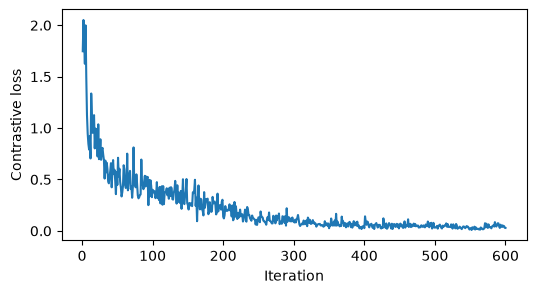

In [ ]:
counter = []
loss_history = []
iteration_number = 0

# 에폭을 돈다
for epoch in range(100):

    # 배치를 돈다
    for i, (img0, img1, label) in enumerate(train_dataloader, 0):

        # 이미지와 레이블을 GPU로 보낸다
        img0, img1, label = img0.to(device), img1.to(device), label.to(device)

        # 기울기를 지운다
        optimizer.zero_grad()

        # 두 이미지를 넣어 두 출력을 얻는다
        output1, output2 = net(img0, img1)

        # 출력과 레이블을 손실 함수에 넣는다
        loss_contrastive = criterion(output1, output2, label)

        # 역전파
        loss_contrastive.backward()

        # 최적화
        optimizer.step()

        iteration_number += 1
        counter.append(iteration_number)
        loss_history.append(loss_contrastive.item())

    # 100번 찍지 않도록 10 에폭마다 출력한다
    if epoch % 10 == 0 or epoch == 99:
        print(f"Epoch {epoch}, 현재 손실 {loss_contrastive.item():.4f}")

show_plot(counter, loss_history)

**테스트합니다.** 학습에 없던 3명의 사진으로 쌍을 만들어 거리(Dissimilarity)를 잽니다. 쌍마다 거리와 실제 레이블을 함께 표시합니다. 실행하면 그림으로 볼 수 있습니다.

In [ ]:
# 테스트 데이터로 쌍 데이터셋을 만든다
folder_dataset_test = datasets.ImageFolder(root=ATT_ROOT / "testing")
siamese_dataset_test = SiameseNetworkDataset(imageFolderDataset=folder_dataset_test, transform=transformation)
test_dataloader = DataLoader(siamese_dataset_test, num_workers=NUM_WORKERS, batch_size=1, shuffle=True)

net.eval()
dataiter = iter(test_dataloader)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
with torch.no_grad():
    for ax in axes.flatten():
        x0, x1, pair_label = next(dataiter)
        output1, output2 = net(x0.to(device), x1.to(device))
        euclidean_distance = F.pairwise_distance(output1, output2)

        # 두 얼굴을 가로로 붙여서 그린다
        ax.imshow(torch.cat((x0[0, 0], x1[0, 0]), dim=1), cmap="gray")
        truth = "different" if pair_label.item() == 1 else "same"
        ax.set_title(f"Dissimilarity: {euclidean_distance.item():.2f}\n({truth})")
        ax.axis("off")
plt.tight_layout()
plt.show()

이 셀의 그림은 데이터 재게시 조건 때문에 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


그림 몇 장으로는 판단할 수 없습니다. 테스트의 30장(3명 × 10장)에서 가능한 모든 쌍의 거리를 재서 같은 사람과 다른 사람을 나눠 봅시다. 두 분포가 얼마나 떨어져 있는지가 이 모델의 실력입니다.

"거리가 얼마보다 작으면 같은 사람"이라는 기준은 **학습 데이터에서 정합니다**. 테스트를 보고 기준을 고르면 시험지를 보고 답을 고치는 셈입니다. 같은 사람 쌍이 다른 사람 쌍보다 훨씬 적으므로, 두 집단의 정답률을 평균한 균형 정확도(balanced accuracy)로 잽니다. 그냥 정확도라면 전부 "다른 사람"이라고 답해도 높게 나옵니다.

학습 사람들: 같은 사람 평균 거리 0.183, 다른 사람 평균 거리 4.815
테스트 사람들: 같은 사람 쌍 135개 평균 거리 0.969, 다른 사람 쌍 300개 평균 거리 3.554
학습에서 고른 기준 거리: 0.675
균형 정확도: 학습 0.999, 테스트 0.659


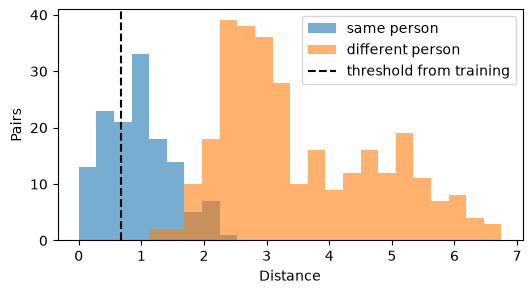

In [ ]:
def embed_folder(network: SiameseNetwork, folder: datasets.ImageFolder, tf: Callable) -> tuple[torch.Tensor, torch.Tensor]:
    """폴더의 모든 이미지를 임베딩으로 바꾸고 레이블과 함께 돌려줍니다."""
    images = torch.stack([tf(Image.open(path).convert("L")) for path, _ in folder.imgs])
    labels = torch.tensor([label for _, label in folder.imgs])
    network.eval()
    with torch.no_grad():
        embeddings = network.forward_once(images.to(device)).cpu()
    return embeddings, labels


def pair_distances(embeddings: torch.Tensor, labels: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """가능한 모든 쌍의 거리를 같은 사람 쌍과 다른 사람 쌍으로 나눕니다."""
    distances = torch.cdist(embeddings, embeddings)
    upper = torch.triu(torch.ones_like(distances, dtype=torch.bool), diagonal=1)  # 자기 자신과 중복 쌍을 뺀다
    same_person = labels[None, :] == labels[:, None]
    return distances[same_person & upper], distances[~same_person & upper]


def balanced_accuracy(same: torch.Tensor, different: torch.Tensor, threshold: float) -> float:
    """기준보다 가까우면 같은 사람으로 판단할 때, 두 집단 정답률의 평균을 돌려줍니다."""
    return (((same < threshold).float().mean() + (different >= threshold).float().mean()) / 2).item()


train_same, train_different = pair_distances(*embed_folder(net, folder_dataset, transformation))
test_same, test_different = pair_distances(*embed_folder(net, folder_dataset_test, transformation))

# 기준 후보를 학습 쌍에서 시험해 가장 좋은 값을 고른다
candidates = torch.linspace(0, float(train_different.max()), 200)
decision_threshold = max(candidates.tolist(), key=lambda t: balanced_accuracy(train_same, train_different, t))

print(f"학습 사람들: 같은 사람 평균 거리 {train_same.mean():.3f}, 다른 사람 평균 거리 {train_different.mean():.3f}")
print(f"테스트 사람들: 같은 사람 쌍 {len(test_same)}개 평균 거리 {test_same.mean():.3f}, 다른 사람 쌍 {len(test_different)}개 평균 거리 {test_different.mean():.3f}")
print(f"학습에서 고른 기준 거리: {decision_threshold:.3f}")
print(f"균형 정확도: 학습 {balanced_accuracy(train_same, train_different, decision_threshold):.3f}, 테스트 {balanced_accuracy(test_same, test_different, decision_threshold):.3f}")

bins = np.linspace(0, float(max(test_same.max(), test_different.max())), 25)
plt.figure(figsize=(6, 3))
plt.hist(test_same.numpy(), bins=bins, alpha=0.6, label="same person")
plt.hist(test_different.numpy(), bins=bins, alpha=0.6, label="different person")
plt.axvline(decision_threshold, color="black", linestyle="--", label="threshold from training")
plt.xlabel("Distance")
plt.ylabel("Pairs")
plt.legend()
plt.show()

학습 사람들과 테스트 사람들의 균형 정확도 차이는, 처음 보는 사람에게 모델이 얼마나 통하는지를 보여 줍니다. 히스토그램에서 두 분포가 겹치는 구간이 모델이 헷갈리는 쌍입니다. 다만 테스트는 3명뿐이고 같은 사진이 여러 쌍에 들어가므로, 숫자는 대략적인 값으로만 보세요.

저장된 출력을 읽어 봅시다. 같은 사람 쌍의 평균 거리가 학습 사람들에서는 0.183인데 처음 보는 사람들에서는 0.969로 크게 늘고, 균형 정확도도 0.999에서 0.659로 떨어집니다. 학습 손실이 0에 가까워도 **처음 보는 사람에게 그만큼 통하는 것은 아닙니다.** 학습 사람들에 과적합된 것입니다. 평균 거리 자체는 테스트에서도 뚜렷이 다르므로(0.969와 3.554) 임베딩이 쓸모없는 것은 아니고, 학습에서 고른 기준(0.675)이 테스트에는 너무 빡빡합니다.

## 4.3 다른 예제: Omniglot

Omniglot은 전 세계 50개 문자 체계의 손글씨 문자를 모은 데이터로, 문자마다 **20명이 쓴 20장** 만 있습니다. 예시가 아주 적을 때 학습하는 one-shot learning의 대표 데이터입니다. 공식 저장소: [brendenlake/omniglot](https://github.com/brendenlake/omniglot)

문제는 이렇습니다. 처음 보는 문자 한 장(query)을 주고, 후보 여러 장 중 **같은 문자를 고르게** 합니다. 학습용 문자 체계(30개)와 평가용 문자 체계(20개)가 달라서 평가 때는 완전히 처음 보는 문자를 만납니다.

아래 모델은 Koch 등의 [Siamese Neural Networks for One-shot Image Recognition](https://www.cs.cmu.edu/~rsalakhu/papers/oneshot1.pdf) 구조를 따른 것입니다. 4.2절과 다른 점은 다음과 같습니다.

- 거리 대신, 두 벡터 차의 절댓값을 선형 층에 넣어 **같은 정도의 점수(logit)** 를 냅니다.
- 그래서 손실로 Contrastive loss가 아니라 `BCEWithLogitsLoss`를 씁니다.
- 레이블은 **같으면 1** 입니다. 4.2절과 반대입니다.

출처: [Omniglot Siamese 예제 (Colab)](https://colab.research.google.com/drive/1TDjk36ia5rTXQPHpAgfwZvPDmXbHetui?usp=sharing)

In [ ]:
class Siamese_Net(nn.Module):
    def __init__(self) -> None:
        super().__init__()

        self.conv1 = nn.Conv2d(1, 64, 10)
        self.conv2 = nn.Conv2d(64, 128, 7)
        self.conv3 = nn.Conv2d(128, 128, 4)
        self.conv4 = nn.Conv2d(128, 256, 4)

        self.Linear1 = nn.Linear(9216, 4096)
        self.flatten = nn.Flatten()
        self.Linear2 = nn.Linear(4096, 1)

        self.relu = nn.ReLU()
        self.maxP = nn.MaxPool2d(2)
        self.sigm = nn.Sigmoid()

        # 논문의 초기화를 시험하려면 아래 줄의 주석을 푸세요. 완전 연결 층 가중치의 표준편차는 논문대로 0.2다
        # self.initialize_weights()

    def twin(self, x: torch.Tensor) -> torch.Tensor:
        out = self.conv1(x)
        out = self.relu(out)
        out = self.maxP(out)

        out = self.conv2(out)
        out = self.relu(out)
        out = self.maxP(out)

        out = self.conv3(out)
        out = self.relu(out)
        out = self.maxP(out)

        out = self.conv4(out)
        out = self.relu(out)

        # out.view(out.size()[0], -1)와 같다
        out = self.flatten(out)

        out = self.Linear1(out)
        out = self.sigm(out)

        return out

    def forward(self, x1: torch.Tensor, x2: torch.Tensor) -> torch.Tensor:
        x1_out = self.twin(x1)
        x2_out = self.twin(x2)

        # 점수 = 선형 층(두 벡터의 거리)
        score = self.Linear2(torch.abs(x1_out - x2_out))

        return score

    def initialize_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, 0, 1e-2)
                nn.init.normal_(m.bias, 0.5, 1e-2)
            if isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 2e-1)
                nn.init.normal_(m.bias, 0.5, 1e-2)

크기를 맞게 계산했는지 가짜 입력으로 시험합니다. 105 → (합성곱 10) 96 → (풀링) 48 → (합성곱 7) 42 → (풀링) 21 → (합성곱 4) 18 → (풀링) 9 → (합성곱 4) 6이므로, 펼치면 $256 \times 6 \times 6 = 9216$입니다.

In [ ]:
net = Siamese_Net()
dummyx1 = torch.randn(64, 1, 105, 105)
dummyx2 = torch.randn(64, 1, 105, 105)
o = net(dummyx1, dummyx2)
print(o.shape)

torch.Size([64, 1])


### Omniglot 데이터셋

In [ ]:
# 데이터셋을 내려받는다. background=True가 학습용(30개 문자 체계), False가 평가용(20개)이다
omni_train = datasets.Omniglot(root="data", background=True, download=True)
omni_test = datasets.Omniglot(root="data", background=False, download=True)
print(len(omni_train), len(omni_test))

19280 13180


데이터셋 클래스입니다. 학습과 검증에서 돌려주는 것이 다릅니다.

- `job="train"`: 쌍 하나와 레이블을 돌려줍니다. 인덱스가 짝수면 같은 문자, 홀수면 다른 문자입니다.
- `job="val"`: N-way 문제 하나를 돌려줍니다. 맨 앞이 query, 그다음이 정답, 나머지가 오답입니다.

구현에서 주의한 점은 다음과 같습니다.

- `get_same`은 `random.sample`로 뽑습니다. `random.choice`를 두 번 쓰면 같은 파일이 두 번 나올 수 있습니다.
- `get_different`는 (문자 체계, 문자 번호)의 쌍으로 비교합니다. 문자 번호는 문자 체계마다 따로 매겨지므로 번호만 비교하면 안 됩니다.
- `os.listdir`는 순서가 일정하지 않고 숨김 파일까지 읽으므로, 폴더만 골라 정렬합니다.
- `limit`으로 한 에폭의 크기를 줄일 수 있습니다. 시험 삼아 돌릴 때 쓰세요.

In [ ]:
class OmniglotPairDataset(Dataset):
    def __init__(
        self,
        root_dir: str | Path,
        job: str = "train",
        ways: int = 10,
        transform: Callable | None = None,
        limit: int | None = None,
    ) -> None:
        super().__init__()
        self.root_dir = Path(root_dir)
        self.job = job
        self.all_classes = sorted(p.name for p in self.root_dir.iterdir() if p.is_dir())
        self.num_classes = len(self.all_classes)
        self.char_paths, self.number_of_images = self.get_char_list()
        self.ways = ways
        self.transform = transform
        self.limit = limit
        print(f"문자 체계 {self.num_classes}개, 이미지 {self.number_of_images}장")

    def __len__(self) -> int:
        return self.number_of_images if self.limit is None else min(self.limit, self.number_of_images)

    def load(self, path: Path) -> torch.Tensor:
        img = Image.open(path).convert("L")
        return self.transform(img) if self.transform else img

    def __getitem__(self, idx: int) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        if self.job == "train":
            # 인덱스가 짝수면 같은 문자, 홀수면 다른 문자
            if idx % 2 == 0:
                is_same = 1
                path_img_1, path_img_2, _ = self.get_same()
            else:
                is_same = 0
                path_img_1, path_img_2 = self.get_different()
            return self.load(path_img_1), self.load(path_img_2), torch.tensor([is_same], dtype=torch.float32)

        # 같은 문자에서 두 장을 고른다
        path_img_1, path_img_2, id_to_avoid = self.get_same()
        img_list = [path_img_1, path_img_2]

        # 나머지는 다른 문자에서 두 장씩 고른다. ways가 10이면 query 1장 + 후보 9장이다
        for _ in range((self.ways - 2) // 2):
            img_list += self.get_different(id_to_avoid)

        return torch.stack([self.load(path) for path in img_list])

    def get_char_list(self) -> tuple[dict[int, list[list[Path]]], int]:
        # 문자 체계 번호 -> 문자별 이미지 경로 목록
        a_list, n_letters = {}, 0
        for idx, alpha in enumerate(self.all_classes):
            a_list[idx] = []
            for char_dir in sorted(p for p in (self.root_dir / alpha).iterdir() if p.is_dir()):
                l_list = sorted(char_dir.glob("*.png"))
                n_letters += len(l_list)
                a_list[idx].append(l_list)
        return a_list, n_letters

    def random_char(self) -> tuple[int, int]:
        alpha_id = random.randint(0, self.num_classes - 1)
        char_id = random.randint(0, len(self.char_paths[alpha_id]) - 1)
        return alpha_id, char_id

    def get_same(self) -> tuple[Path, Path, tuple[int, int]]:
        alpha_id, char_id = self.random_char()
        # 같은 파일이 두 번 뽑히지 않도록 sample을 쓴다
        path_img_1, path_img_2 = random.sample(self.char_paths[alpha_id][char_id], 2)
        return path_img_1, path_img_2, (alpha_id, char_id)

    def get_different(self, avoid: tuple[int, int] | None = None) -> list[Path]:
        first = self.random_char()
        while first == avoid:
            first = self.random_char()

        second = self.random_char()
        while second == first or second == avoid:
            second = self.random_char()

        path_img_1 = random.choice(self.char_paths[first[0]][first[1]])
        path_img_2 = random.choice(self.char_paths[second[0]][second[1]])
        return [path_img_1, path_img_2]

검증 데이터의 모양이 어떻게 될지 미리 봅시다. `torch.stack`은 같은 모양의 텐서들을 **새 차원** 으로 쌓습니다. 이미지 묶음 10장을 쌓아 N-way 문제 하나를 만드는 데 씁니다.

In [ ]:
a = torch.randn((64, 3, 122, 450), dtype=torch.float32)
b = torch.randn((64, 3, 122, 450), dtype=torch.float32)
c_tensor = torch.randn((64, 3, 122, 450), dtype=torch.float32)
l = [a, b, c_tensor]
lt = torch.stack(l)
print(lt.shape)
print(lt[0, :].shape)

torch.Size([3, 64, 3, 122, 450])
torch.Size([64, 3, 122, 450])


In [ ]:
# Omniglot 폴더
train_root = "data/omniglot-py/images_background"
val_root = "data/omniglot-py/images_evaluation"
batch_size = 16
ways = 10

정규화에 쓸 평균과 표준편차를 구합니다. Omniglot은 흰 바탕에 검은 글씨라 평균이 1에 가깝습니다.

In [ ]:
def find_mean_std(pair_datasets: list[Dataset], batch_s: int = 1) -> list[torch.Tensor]:
    """데이터셋마다 평균과 표준편차를 구합니다. 각 쌍의 첫 이미지만 씁니다."""
    means_stds = []
    for dataset in pair_datasets:
        to_norm_loader = DataLoader(dataset=dataset, batch_size=batch_s)
        print("전체 샘플 수: ", len(dataset))

        channels_sum, channels_squared_sum, num_batches = 0, 0, 0
        for img, _, __ in to_norm_loader:
            # img의 모양은 [batch, C, H, W]
            channels_sum += torch.mean(img, dim=[0, 2, 3])
            channels_squared_sum += torch.mean(img ** 2, dim=[0, 2, 3])
            num_batches += 1

        mean = channels_sum / num_batches
        std = (channels_squared_sum / num_batches - mean ** 2) ** 0.5
        means_stds.append(mean)
        means_stds.append(std)
    return means_stds


plain_transform = transforms.Compose([transforms.Resize((105, 105)), transforms.ToImage(), transforms.ToDtype(torch.float32, scale=True)])
to_be_norm_dataset = OmniglotPairDataset(train_root, transform=plain_transform)
to_be_norm_dataset_val = OmniglotPairDataset(val_root, transform=plain_transform)

mean, std, mean_val, std_val = find_mean_std([to_be_norm_dataset, to_be_norm_dataset_val], batch_s=batch_size)

print(f"mean: {mean.item():.4f}  std: {std.item():.4f}  val mean: {mean_val.item():.4f}  val std: {std_val.item():.4f}")

문자 체계 30개, 이미지 19280장
문자 체계 20개, 이미지 13180장
전체 샘플 수:  19280


전체 샘플 수:  13180


mean: 0.9245  std: 0.2642  val mean: 0.9175  val std: 0.2751


학습 데이터에는 `RandomAffine`으로 회전과 기울임을 줍니다. `shear`의 단위는 **도(degree)** 입니다. `shear=0.2`라고 쓰면 0.2도라 105칸에서 0.4픽셀도 밀리지 않아 사실상 기울임이 없습니다. 흔한 실수입니다. 여기서는 0.2라디안에 해당하는 약 11.5도를 씁니다. 참고로 논문은 회전 ±10도, 기울임 ±0.3이고 각 변환을 확률 0.5로 적용합니다. 여기서 쓰는 회전 ±30도는 논문보다 강합니다. 회전하면 모서리에 빈 곳이 생기는데, 기본값은 검은색(0)으로 채웁니다. 이 데이터는 **바탕이 흰색** 이라 `fill=255`를 줍니다. 그대로 두면 글씨가 아니라 검은 모서리가 입력의 큰 특징이 됩니다.

평가 데이터도 자기 평균이 아니라 **학습 데이터의 평균과 표준편차** 로 정규화합니다. 실제 사용할 때는 새 데이터의 통계를 미리 알 수 없기 때문입니다. 값의 차이는 작지만 원칙을 지킵니다.

아래 `TRAIN_LIMIT`과 `VAL_LIMIT`은 한 에폭의 크기입니다. `None`이면 전체(학습 19,280쌍, 검증 13,180문제)를 씁니다.

In [ ]:
# OMNIGLOT 데이터셋을 준비한다
TRAIN_LIMIT = None
VAL_LIMIT = None
ROTATION_DEGREES = 30
SHEAR_DEGREES = math.degrees(0.2)  # shear의 단위가 도이므로 0.2라디안을 도로 바꾼다
WHITE_FILL = 255

transform = transforms.Compose([
    transforms.Resize((105, 105)),
    transforms.RandomAffine(ROTATION_DEGREES, shear=SHEAR_DEGREES, fill=WHITE_FILL),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize([mean.item()], [std.item()]),
])
eval_transform = transforms.Compose([
    transforms.Resize((105, 105)),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize([mean.item()], [std.item()]),
])

dataset_train = OmniglotPairDataset(train_root, transform=transform, limit=TRAIN_LIMIT)
dataset_val = OmniglotPairDataset(val_root, job="val", ways=ways, transform=eval_transform, limit=VAL_LIMIT)

dataloader_train = DataLoader(dataset=dataset_train, batch_size=batch_size)
dataloader_val = DataLoader(dataset=dataset_val, batch_size=batch_size)

문자 체계 30개, 이미지 19280장
문자 체계 20개, 이미지 13180장


### 데이터셋이 제대로 동작하는지 확인하기

학습 전에 눈으로 확인하는 습관을 들이세요. 인덱스 1은 홀수이므로 다른 문자 쌍입니다. 레이블이 0이어야 합니다.

0.0
torch.Size([1, 105, 105]) 
 torch.Size([1, 105, 105])
(105, 105) 
 (105, 105)


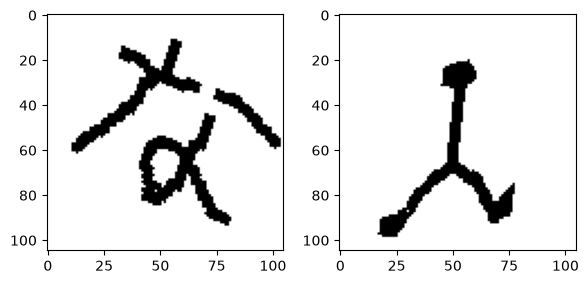

In [ ]:
# 학습 데이터셋 시험
img1, img2, are_Same = dataset_train[1]

print(are_Same.item())
print(img1.shape, "\n", img2.shape)

# 눈으로 보기 위해서만 정규화를 되돌려 PIL 이미지로 바꾼다
show_img1 = transforms.ToPILImage()(img1.mul_(std).add_(mean))
show_img2 = transforms.ToPILImage()(img2.mul_(std).add_(mean))

print(show_img1.size, "\n", show_img2.size)

plt.figure(figsize=(6, 3))
plt.subplot(121)
plt.imshow(show_img1, cmap="gray")
plt.subplot(122)
plt.imshow(show_img2, cmap="gray")
plt.tight_layout()
plt.show()

검증 데이터셋입니다. 첫 줄의 첫 번째가 query이고, 두 번째가 같은 문자여야 합니다. 나머지는 모두 다른 문자입니다. 후보는 첫 칸을 뺀 **9장** 이므로, `ways=10`이라는 이름과 달리 실제로는 9지선다입니다. 찍어서 맞힐 확률은 $1/9 \approx 11\%$입니다.

torch.Size([10, 1, 105, 105]) torch.Size([1, 105, 105])


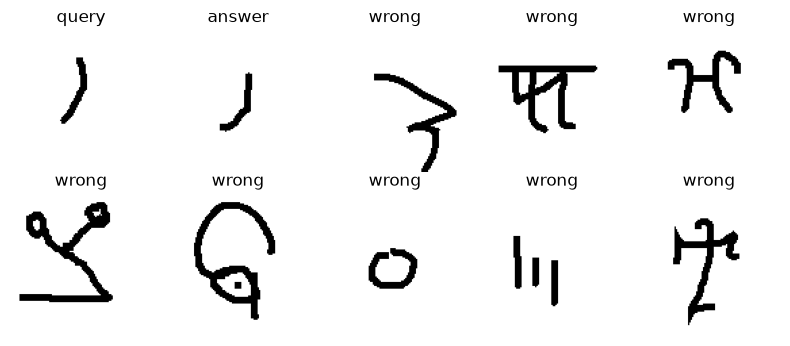

In [ ]:
imgs = dataset_val[0]

print(imgs.shape, imgs[0, :].shape)

plt.figure(figsize=(8, 3.5))
for i in range(ways):
    img = imgs[i, :]
    plt.subplot(2, 5, i + 1)
    plt.imshow(transforms.ToPILImage()(img.mul_(std).add_(mean)), cmap="gray")
    plt.title("query" if i == 0 else "answer" if i == 1 else "wrong")
    plt.axis("off")
plt.tight_layout()
plt.show()

### 학습

**N-way 정확도를 재는 함수** 부터 만듭니다. query와 후보를 하나씩 비교해 점수가 가장 큰 후보를 고릅니다. 정답은 언제나 첫 후보(인덱스 0)입니다.

시그모이드를 지난 값으로 비교하면 안 됩니다. 점수가 큰 후보들은 시그모이드에서 모두 1.0으로 뭉칠 수 있고, 그러면 `argmax`가 동률 중 앞쪽을 골라 정답이 항상 첫 칸인 이 문제에서 정확도가 부풀 수 있습니다. 그래서 **시그모이드를 거치지 않은 logit** 을 비교합니다. 배치별 정확도의 평균도 마지막 작은 배치에 왜곡되므로, 맞힌 개수를 전체 개수로 나눕니다. 학습 정확도를 재는 뒤쪽 코드에도 같은 계산이 필요해 함수로 묶었습니다.

In [ ]:
def one_shot_accuracy(model: nn.Module, loader: DataLoader, ways: int) -> float:
    """N-way 문제에서 query와 가장 비슷하다고 판단한 후보가 정답인 비율을 잽니다."""
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images in loader:
            images = images.to(device)
            query = images[:, 0, :]
            # 모양: [후보 수, 배치, 1]
            scores = torch.stack([model(query, images[:, i, :]) for i in range(1, ways)])
            results = torch.argmax(scores, 0)
            correct += (results == 0).sum().item()
            total += images.shape[0]
    return correct / total

> **학습 시간 안내**: 원래 설정은 81 에폭(0~80)입니다. 전체 데이터로 한 에폭의 학습만 1,205배치인데, 이 교재를 검증한 Apple Silicon Mac에서 배치당 약 0.14초였으므로 학습만 약 3분입니다. 여기에 매 에폭 검증이 더해지니, 끝까지 돌리면 몇 시간 규모로 예상하세요. Colab GPU에서는 재 보지 못했습니다. 빠르게 시험하려면 위 셀의 `TRAIN_LIMIT`, `VAL_LIMIT`과 아래의 `epochs`를 줄이세요. 체크포인트를 저장해 두었다가 `resume_training = True`로 이어서 학습할 수도 있습니다.
>
> **이 노트북에 저장된 출력은 검증용으로 줄인 짧은 실행입니다**(0~4의 5 에폭, 학습 3,200쌍, 검증 800문제). 저장된 20~30%대 정확도는 **이 모델의 실력이 아닙니다**. 코드가 돌아가고 찍기(11%)보다 낫다는 것만 보여 줍니다. 곡선이 어디까지 오르는지는 직접 끝까지 돌려 확인하세요. 참고로 저자가 전체 데이터로 14 에폭까지 돌렸을 때 검증 정확도는 첫 에폭 약 60%, 14 에폭 무렵 약 84%였습니다. 이 노트북과 일부 설정이 다른 실행이라 대략의 감만 잡으세요.

In [ ]:
# 이어서 학습하려면 True로 바꾼다. checkpoints/의 최신 파일에서 이어 간다
resume_training = False

체크포인트는 작업 폴더의 `checkpoints/`에 저장합니다. Colab은 세션이 끝나면 이 폴더가 지워지므로, 오래 학습한다면 내려받아 두세요. 20 에폭마다 저장하는데, 파일 하나가 수백 MB(가중치와 Adam 상태)라 디스크가 금방 차므로 **최신 하나만** 남깁니다. 중간 모델을 비교하고 싶다면 학습 셀에서 지우는 줄을 빼세요. **주의**: `resume_training = False`로 처음부터 다시 돌리면 첫 저장 직후 이전 체크포인트가 지워집니다. 끝까지 학습한 파일이 있다면 먼저 다른 곳에 옮겨 두세요.

In [ ]:
CKPT_DIR = Path("checkpoints")
CKPT_DIR.mkdir(exist_ok=True)

set_seed()
model = Siamese_Net().to(device)

loss_function = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=3e-4, weight_decay=6e-5)

# 학습률 스케줄러를 시험하려면 주석을 푸세요(2강 3.7절). 아래 학습 셀의 해당 줄도 함께 풉니다
# lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=4)
# lr_scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.99)

start_epoch = 0
epochs = 80

if resume_training:
    # 학습 셀이 최신 체크포인트 하나만 남기므로 그것을 찾는다
    latest_checkpoint = max(CKPT_DIR.glob("checkp*.pt"), key=lambda path: int(path.stem.removeprefix("checkp")))
    checkpoint = torch.load(latest_checkpoint, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    # 저장된 에폭은 이미 끝났으므로 그다음부터 시작한다
    start_epoch = checkpoint["epoch"] + 1

In [ ]:
t_loss, accuracy_history = [], []
val_every = 1
save_every = 20

for epoch in range(start_epoch, epochs + 1):
    t_loss_batch = []

    # ---------------------- 학습 ----------------------
    model.train()
    for batch_idx, (img1, img2, isSame) in enumerate(dataloader_train):
        img1, img2, isSame = img1.to(device), img2.to(device), isSame.to(device)

        # 기울기 초기화
        optimizer.zero_grad()

        # 순전파
        scores = model(img1, img2)
        loss = loss_function(scores, isSame)

        # 역전파
        loss.backward()

        # 가중치 갱신
        optimizer.step()

        t_loss_batch.append(loss.item())

    mean_loss = sum(t_loss_batch) / len(t_loss_batch)
    t_loss.append(mean_loss)

    # ---------------------- 학습률 스케줄러 ----------------------
    # ExponentialLR을 쓴다면
    # lr_scheduler.step()

    # ReduceLROnPlateau를 쓴다면
    # lr_scheduler.step(mean_loss)

    # ---------------------- 검증 ----------------------
    if epoch % val_every == 0:
        accuracy_history.append(one_shot_accuracy(model, dataloader_val, ways))
        print(f"Epoch {epoch}: 학습 손실 {t_loss[-1]:.4f}, 검증 정확도 {accuracy_history[-1] * 100:.2f}%")

    # 마지막 에폭도 저장해야 아래의 학습 정확도 셀에서 불러올 수 있다
    if epoch % save_every == 0 or epoch == epochs:
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "loss": t_loss[-1],
            },
            CKPT_DIR / f"checkp{epoch}.pt",
        )
        # 파일 하나가 수백 MB이므로 방금 저장한 것만 남긴다
        for old_checkpoint in CKPT_DIR.glob("checkp*.pt"):
            if old_checkpoint.name != f"checkp{epoch}.pt":
                old_checkpoint.unlink()

Epoch 0: 학습 손실 0.6304, 검증 정확도 20.38%


Epoch 1: 학습 손실 0.5894, 검증 정확도 30.63%


Epoch 2: 학습 손실 0.5558, 검증 정확도 30.75%


Epoch 3: 학습 손실 0.5356, 검증 정확도 25.12%


Epoch 4: 학습 손실 0.5289, 검증 정확도 27.75%


평균 손실: 0.568
평균 정확도: 26.925%, 최고 정확도: 30.750%


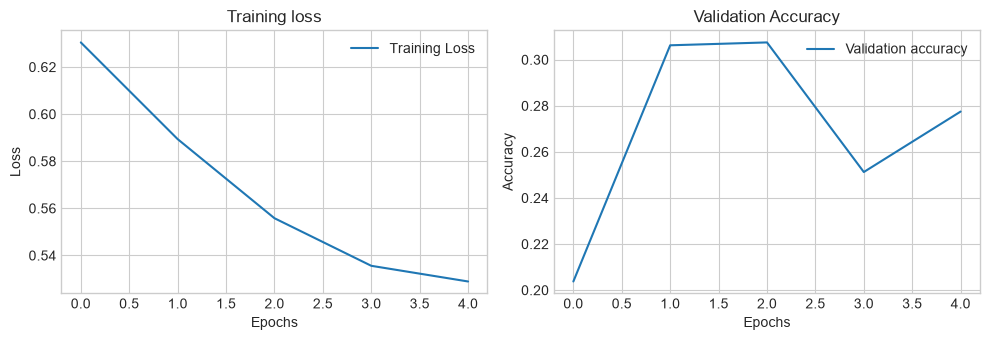

In [ ]:
# 학습 손실과 검증 정확도 그래프
print(f"평균 손실: {sum(t_loss) / len(t_loss):.3f}")
print(f"평균 정확도: {sum(accuracy_history) / len(accuracy_history) * 100:.3f}%, 최고 정확도: {max(accuracy_history) * 100:.3f}%")

with plt.style.context("seaborn-v0_8-whitegrid"):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(t_loss, label="Training Loss")
    axes[0].legend()
    axes[0].set_title("Training loss")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Loss")
    axes[1].plot(accuracy_history, label="Validation accuracy")
    axes[1].legend()
    axes[1].set_title("Validation Accuracy")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Accuracy")
    plt.tight_layout()
    plt.show()

**학습 문자 체계에서의 정확도** 도 재 봅니다. 저장한 마지막 체크포인트를 불러와, 학습에 쓴 문자 체계로 같은 9지선다를 풉니다. 검증 정확도와의 차이가 과적합의 정도입니다. 저장된 출력은 짧은 실행이라 차이를 해석할 수 없습니다. 끝까지 학습한 뒤 비교하세요.

In [ ]:
model = Siamese_Net().to(device)
checkpoint = torch.load(CKPT_DIR / f"checkp{epochs}.pt", map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])

dataset_train_acc = OmniglotPairDataset(train_root, job="val", ways=ways, transform=eval_transform, limit=VAL_LIMIT)
dataloader_train_acc = DataLoader(dataset=dataset_train_acc, batch_size=batch_size)

train_accuracy = one_shot_accuracy(model, dataloader_train_acc, ways)
print(f"학습 문자 체계 정확도: {train_accuracy * 100:.3f}%")

문자 체계 30개, 이미지 19280장


학습 문자 체계 정확도: 34.375%


---
# 5교시. 웹앱 만들기: Teachable Machine + Netlify

지금까지 만든 모델은 노트북 안에만 있습니다. 이번에는 다른 사람이 **브라우저로 쓸 수 있는** 이미지 분류 웹앱을 만듭니다. 이 교시는 카메라와 계정이 필요한 수동 작업이 많아, 절차를 따라 직접 해 봐야 합니다. 서비스 화면은 바뀔 수 있으니 메뉴 이름이 다르면 비슷한 항목을 찾으세요.

## 5.1 Teachable Machine이란?

[Teachable Machine](https://teachablemachine.withgoogle.com)은 웹에서 손쉽게 데이터를 모으고, 모델을 학습하고 내보낼 수 있게 해 주는 서비스입니다.

**사용법**

- 데이터를 모읍니다.
- 데이터를 이용해 모델을 학습시킵니다.
- 학습된 모델을 내보내(export) 원하는 곳에 적용합니다.

**학습 가능한 데이터**

- 이미지: 예) 강아지? 고양이?
- 오디오: 예) 박수 소리? 스냅 소리?
- 포즈: 예) 앉은 자세? 선 자세?

## 5.2 모델 학습

매우 간단하게 학습할 수 있습니다. 여기서는 이미지 모델로 하지만 오디오와 포즈도 같은 방식입니다.

1. **프로젝트 고르기**: 이미지/오디오/포즈 중 필요한 것을 고릅니다. 이미지라면 표준 이미지 모델(Standard image model)을 선택합니다.
2. **클래스별로 데이터 추가**
    - 카메라로 이미지를 캡처할 수 있습니다.
    - 이미지 파일을 업로드하거나 Google Drive에서 가져올 수 있습니다.
3. **데이터 확인 및 정제**
    - 데이터를 넣으면 입력된 이미지들이 클래스 카드에 보입니다.
    - 부적절한 데이터가 들어가 있으면 학습에 악영향을 줍니다. 확인한 뒤 삭제할 것은 삭제하세요.
4. **모델 학습시키기**
    - 데이터를 모으고 정제했다면 학습 버튼을 누릅니다.
    - 버튼이 활성화되지 않으면 데이터의 양이 너무 적지 않은지 확인하세요.
    - **Q. 데이터가 얼마나 있으면 되나요?**
      <details><summary>답</summary>

      가능한 한 많이 모으는 것이 좋습니다. 다만 많을수록 학습 시간이 길어집니다. 몇 백 장까지는 매우 빠르게 학습이 진행됩니다. 실제 딥러닝에서는 모델의 복잡도도 함께 고려해야 합니다.

      </details>
5. **하이퍼파라미터 설정(선택)**
    - **Epoch(에폭)**: 전체 학습 데이터를 한 번 학습하는 주기입니다. 예를 들어 10 에폭이면 전체 데이터를 10번 반복해 학습합니다.
    - **Batch Size(배치 크기)**: 한 번에 처리하는 샘플 수입니다. 작으면 메모리를 적게 쓰지만 학습이 오래 걸릴 수 있습니다. 크면 학습이 빠르지만 메모리가 더 필요합니다.
    - **Learning Rate(학습률)**: 가중치를 갱신할 때 얼마나 큰 보폭으로 이동할지 정합니다. 작으면 안정적이지만 수렴이 느립니다. 크면 빠르게 수렴할 수 있지만 발산할 위험이 있습니다.
6. **모델 성능 테스트**
    - 다양한 환경에서 다양한 대상을 비춰 분류 성능을 시험합니다.
    - 분류가 잘 안 되면 그런 데이터를 학습 데이터에 추가합니다.
7. **모델 내보내기**
    - "모델 내보내기"로 모델을 다운로드하거나, 업로드해 링크로 어디에나 적용할 수 있습니다. 업로드가 조금 더 간편합니다(추천).
    - Tensorflow.js, Tensorflow, Tensorflow Lite 중에서 고릅니다.
    - 이미지, 오디오, 포즈마다 지원하는 내보내기 종류가 다르지만 `.js`는 모두 됩니다(웹 배포 가능한 버전).
    - Netlify로 배포하려면 `.js`를 고릅니다.
    - 스니펫 코드가 제공되므로 약간만 고치면 원하는 대로 적용할 수 있습니다.
8. **모델 업데이트**: 데이터를 추가해 다시 학습했다면 다음과 같이 합니다.
    - 모델을 다운로드했었다면 새로 학습한 모델을 다시 다운로드합니다.
    - 모델을 업로드했었다면 "클라우드 모델 업데이트"를 눌러 갱신합니다.

## 5.3 Netlify로 배포하기

1. 새 폴더를 만듭니다.
2. 폴더 안에 `index.html` 파일을 만듭니다. VS Code 같은 에디터로 폴더를 열고 만드세요. **파일 이름은 꼭 `index.html`이어야 합니다.**
3. VS Code에서는 `index.html`에 느낌표(`!`)를 입력하고 Enter를 치면 HTML 기본 양식이 완성됩니다.
4. `body` 태그 안에 Teachable Machine의 스니펫 코드를 붙여 넣습니다.
5. 코드의 출력 부분을 고쳐 원하는 동작을 하게 합니다(아래 예시).
6. [Netlify](https://www.netlify.com)로 배포합니다. HTML 파일이 담긴 폴더를 끌어다 놓으면 사이트 주소가 생성됩니다.
    - 가장 빠른 길은 [Netlify Drop](https://app.netlify.com/drop)에 폴더를 끌어다 놓는 것입니다.
    - 또는 회원 가입 → 로그인 → 새 사이트 추가 → 수동 배포(Deploy manually)를 선택해 폴더를 업로드합니다. ([공식 문서](https://docs.netlify.com/deploy/create-deploys/))

이제 직접 만든 사이트에서 모델을 쓸 수 있습니다. 원한다면 AI 도구에 부탁해 CSS를 꾸며 봐도 좋습니다. 카메라는 HTTPS 사이트에서 동작하고, Netlify가 준 주소는 HTTPS입니다. PC에서 파일을 바로 열면 브라우저에 따라 카메라가 막힐 수 있습니다.

아래 셀은 스니펫을 담은 `index.html`을 만들어 `site/` 폴더에 저장합니다. Colab 왼쪽의 파일 창에서 내려받아도 되고, 내용을 복사해도 됩니다. `MODEL_URL`을 **자기 모델의 링크** 로 바꿔야 동작합니다. 라이브러리 사용법은 [Teachable Machine 라이브러리 문서](https://github.com/googlecreativelab/teachablemachine-community/tree/master/libraries/image)에 있습니다.

Teachable Machine이 보여 주는 스니펫은 라이브러리 주소가 `@latest`일 수 있습니다. 이 라이브러리가 요구하는 `tfjs` 버전은 1.3.1이므로, 아래 코드는 `@tensorflow/tfjs@1.3.1`, `@teachablemachine/image@0.8.5`로 고정합니다. 공개된 예시 모델과 Chromium의 가짜 카메라로 예측까지 나오는 것을 시험했습니다(`@latest`도 그 시험은 통과했지만, 버전이 바뀌면 깨질 수 있습니다).

In [ ]:
MODEL_URL = "https://teachablemachine.withgoogle.com/models/YOUR_MODEL_ID/"

INDEX_TEMPLATE = """<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Document</title>
</head>
<body>
    <div>Teachable Machine Image Model</div>
<button type="button" onclick="init()">Start</button>
<div id="webcam-container"></div>
<div id="label-container"></div>
<script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@1.3.1/dist/tf.min.js"></script>
<script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@0.8.5/dist/teachablemachine-image.min.js"></script>
<script type="text/javascript">
    // Teachable Machine 내보내기 창에서 받은 모델 링크
    const URL = "__MODEL_URL__";

    let model, webcam, labelContainer, maxPredictions;

    // 이미지 모델을 불러오고 웹캠을 준비한다
    async function init() {
        const modelURL = URL + "model.json";
        const metadataURL = URL + "metadata.json";

        // 모델과 메타데이터를 불러온다.
        // 파일 선택기나 로컬 파일을 쓰려면 tmImage.loadFromFiles()를 참고한다
        model = await tmImage.load(modelURL, metadataURL);
        maxPredictions = model.getTotalClasses();

        // 웹캠을 준비하는 편의 함수
        const flip = true; // 좌우 반전 여부
        webcam = new tmImage.Webcam(200, 200, flip); // 너비, 높이, 반전
        await webcam.setup(); // 카메라 권한을 요청한다
        await webcam.play();
        window.requestAnimationFrame(loop);

        // 화면에 요소를 붙인다
        document.getElementById("webcam-container").appendChild(webcam.canvas);
        labelContainer = document.getElementById("label-container");
        for (let i = 0; i < maxPredictions; i++) { // 클래스별 레이블
            labelContainer.appendChild(document.createElement("div"));
        }
    }

    async function loop() {
        webcam.update(); // 웹캠 프레임을 갱신한다
        await predict();
        window.requestAnimationFrame(loop);
    }

    // 웹캠 이미지를 모델에 넣는다
    async function predict() {
        // predict는 image, video, canvas 요소를 받을 수 있다
        const prediction = await model.predict(webcam.canvas);
        for (let i = 0; i < maxPredictions; i++) {
            const classPrediction =
                prediction[i].className + ": " + prediction[i].probability.toFixed(2);
            labelContainer.childNodes[i].innerHTML = classPrediction;
        }
    }
</script>

</body>
</html>
"""

SITE_DIR = Path("site")
SITE_DIR.mkdir(exist_ok=True)
(SITE_DIR / "index.html").write_text(INDEX_TEMPLATE.replace("__MODEL_URL__", MODEL_URL), encoding="utf-8")
print((SITE_DIR / "index.html").stat().st_size, "바이트를 저장했습니다")

2644 바이트를 저장했습니다


### 출력 부분 고치기

스니펫은 클래스별 확률을 그대로 보여 줍니다. 다음 예시는 표정 분류 모델의 판단에 따라 사용자에게 말을 건넵니다.

1. `prediction` 상수에 모델의 예측 결과가 들어 있습니다.
2. 예측한 클래스의 이름과 확률을 가져와, 특정 클래스일 확률이 정한 값을 넘는지 확인합니다. 예시는 smile, frown, normal 각각의 확률이 0.6을 넘는지 검사합니다.
3. 넘으면 원하는 동작을 합니다. 웃으면 좋다고, 찌푸리면 왜 표정이 안 좋냐고, 안 웃으면 웃으라고 텍스트로 출력합니다.

`predict` 함수 안을 이렇게 고칠 수 있습니다. **자기 모델의 클래스 이름에 맞추세요.** 이름이 다르면 반응하지 않습니다.

```javascript
async function predict() {
    const prediction = await model.predict(webcam.canvas);
    const messages = { smile: "좋아요!", frown: "왜 표정이 안 좋아요?", normal: "웃어 보세요!" };
    for (let i = 0; i < maxPredictions; i++) {
        const { className, probability } = prediction[i];
        if (probability > 0.6 && messages[className]) {
            labelContainer.childNodes[0].innerHTML = messages[className];
        }
    }
}
```

### 실습 7. 판단 규칙을 파이썬으로 확인하기

배포 전에 판단 규칙을 파이썬으로 시험해 봅시다. Teachable Machine의 `prediction`처럼 `{"className": ..., "probability": ...}`의 리스트를 받아, 위 코드의 메시지를 돌려주는 `choose_message`를 만드세요. 어느 클래스도 기준을 넘지 못하면 `None`을 돌려줍니다.

그다음 **직접 배포** 까지 해 보세요. 클래스 2개 이상인 자기 모델을 Teachable Machine에서 만들고, Netlify 주소를 스마트폰으로 열어 동작을 확인하면 이번 강의의 프로젝트가 끝납니다.

In [ ]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
CONFIDENCE_THRESHOLD = 0.6
MESSAGES = {"smile": "좋아요!", "frown": "왜 표정이 안 좋아요?", "normal": "웃어 보세요!"}


def choose_message(prediction: list[dict[str, float | str]], threshold: float = CONFIDENCE_THRESHOLD) -> str | None:
    for item in prediction:
        if item["probability"] > threshold and item["className"] in MESSAGES:
            return MESSAGES[item["className"]]
    return None


assert choose_message([{"className": "smile", "probability": 0.9}, {"className": "frown", "probability": 0.1}]) == "좋아요!"
assert choose_message([{"className": "smile", "probability": 0.5}, {"className": "frown", "probability": 0.5}]) is None
print("규칙이 맞습니다")
```

</details>

---
## 오늘의 요약

- 역전파는 체인 룰을 뒤에서 앞으로 적용하는 것입니다. 직접 구현했을 때는 **`autograd`와 비교해 검증** 하세요.
- `nn.Module`, `optim`, `Dataset`, `DataLoader`는 각각 파라미터 관리, 갱신, 데이터 묶기, 배치 나누기를 덜어 줍니다. 층을 파이썬 리스트에 담으면 파라미터가 등록되지 않습니다.
- 합성곱은 국소 연결과 가중치 공유로 파라미터를 크게 줄입니다. PyTorch의 합성곱은 수학적으로 **교차상관** 입니다.
- 출력 크기는 $\lfloor (n + 2p - d(k-1) - 1) / s \rfloor + 1$입니다. 풀링은 채널별로 가로세로만 줄입니다.
- **모델과 데이터는 같은 장치에** 있어야 합니다.
- Siamese Network는 같은 신경망을 두 번 써서 임베딩을 비교합니다. Contrastive loss는 절대 거리, Triplet loss는 상대 거리를 학습합니다.
- 임베딩 비교는 지금도 표준입니다. 얼굴 인식은 [ArcFace](https://arxiv.org/abs/1801.07698) 같은 각도 마진 손실을 많이 쓰고, 일반 이미지 검색은 사전학습 모델의 임베딩과 코사인 유사도(`F.cosine_similarity`)로 먼저 시도합니다.
- 레이블의 뜻(같으면 1인지 다르면 1인지)은 코드마다 다릅니다. 손실 식과 함께 확인하세요.
- Teachable Machine과 Netlify로 코드 몇 줄 없이 분류 웹앱을 배포할 수 있습니다.

## 숙제

1. **나만의 웹앱**: 클래스 2개 이상인 Teachable Machine 모델을 만들어 Netlify로 배포하고, 잘 안 되는 경우와 그 이유를 적어 보세요.
2. **활성화 함수 실험**: 3.7절의 비교에 ELU와 GELU를 더하고, 은닉층을 5개로 늘려 다시 비교하세요. 시그모이드는 어떻게 달라지나요?
3. **Triplet으로 얼굴 비교**: 4.2절의 데이터셋을 (anchor, positive, negative)를 돌려주도록 바꾸고 `nn.TripletMarginLoss`로 학습하세요. 같은 사람과 다른 사람의 거리 분포를 Contrastive loss 결과와 비교하세요.
4. **Omniglot 끝까지**: `epochs`와 `limit`을 조절해 4.3절을 돌리고, 검증 정확도 곡선과 학습 문자 체계 정확도를 비교하세요. 과적합이 보이나요?

## 더 읽을거리

- [PyTorch 튜토리얼: What is torch.nn really?](https://pytorch.org/tutorials/beginner/nn_tutorial.html)
- [CS231n: Convolutional Neural Networks](https://cs231n.github.io/convolutional-networks/)
- [A guide to convolution arithmetic for deep learning](https://arxiv.org/abs/1603.07285)
- [Koch et al., Siamese Neural Networks for One-shot Image Recognition](https://www.cs.cmu.edu/~rsalakhu/papers/oneshot1.pdf)
- [Schroff et al., FaceNet (Triplet loss)](https://arxiv.org/abs/1503.03832)